In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from io import StringIO

# Enable LaTeX rendering
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11


In [13]:
# Conversion factors
IN_TO_CM = 2.54
IN_TO_MM = 25.4
LB_TO_N = 4.44822
INLB_TO_NM = 0.112985

In [47]:

# Body Loads Data
body_data_065 = """0	0	0	0	0
3.387	0.360097259	0.717208525	1.338453493	2.665808279
9	1.183634642	5.141717009	4.399477864	19.11136204
14	1.905157475	13.12841739	7.081322092	48.7973059
17.322	2.194568859	19.90414033	8.157041688	73.98214086
21.083	2.162931045	28.12756478	8.039446393	104.5479696
25.138	1.907055588	36.46981097	7.088377229	135.5554496
30.799	1.706014858	46.75990902	6.341124479	173.8029434
32.6	1.637289501	49.77535271	6.085677675	185.011113
37.5572	1.055539174	56.54032626	3.923356976	210.1559932
42.5144	0.320986527	60.04177231	1.193081946	223.1705958
47.4716	-0.581765397	59.4859342	-2.162376712	221.1045887
52.4288	-1.633990276	54.08355164	-6.073414714	201.0243531
57.386	-2.857743797	43.04086795	-10.62201133	159.9795571
62.571	5.191947401	52.42685916	19.2980645	194.8665561
64.048	5.074283332	60.01083923	18.86071631	223.0556199
66.134	4.322058838	69.82863966	16.0647564	259.5476202
71.349	3.112747154	89.28550467	11.56983897	331.8672735
76.6	2.457482624	103.945243	9.134271692	386.3563801
78.3	2.17686405	107.8890375	8.091234289	401.0151573
82.9245	0.638889775	114.4610491	2.374703582	425.442813
87.549	-0.98821012	113.7137682	-3.673100121	422.6652281
92.1735	-2.75019054	105.1309361	-10.22224424	390.763509
96.798	-4.598190664	88.20007672	-17.09111691	327.8328222
101.4225	-6.556640904	62.46775252	-24.37052406	232.1877754
106.506	-8.660188917	23.86065359	-32.18924834	88.68819276
113.697	0	0	0	0"""

body_df_065 = pd.read_csv(StringIO(body_data_065), sep='\t', header=None, 
                           names=['station_in', 'one_sigma_shear_lb', 'one_sigma_moment_inlb', 
                                  'design_shear_lb', 'design_moment_inlb'])

# Add SI unit conversions
body_df_065['station_cm'] = body_df_065['station_in'] * IN_TO_CM
body_df_065['one_sigma_shear_N'] = body_df_065['one_sigma_shear_lb'] * LB_TO_N
body_df_065['one_sigma_moment_Nm'] = body_df_065['one_sigma_moment_inlb'] * INLB_TO_NM
body_df_065['design_shear_N'] = body_df_065['design_shear_lb'] * LB_TO_N
body_df_065['design_moment_Nm'] = body_df_065['design_moment_inlb'] * INLB_TO_NM

# Axial Force Data
axial_data_065 = """3.387	-4.945068092
9	-6.374116554
14	-8.160427132
17.322	-16.56659456
21.083	-31.71133718
25.138	-74.41443373
30.799	-92.95435102
32.6	-97.67131328
37.5572	-130.0906368
42.5144	-162.1737135
47.4716	-194.593037
52.4288	-226.6761138
57.386	-259.0954373
62.571	-307.7378162
64.048	-310.288032
66.134	-325.9861736
71.349	-349.4388865
76.6	-360.9772557
76.6012	198.7227443
78.3	174.4718173
82.9245	150.557137
87.549	126.30621
92.1735	102.3915297
96.798	78.47684938
101.4225	54.22592236
106.506	4.656716145
113.697	0"""

axial_df_065 = pd.read_csv(StringIO(axial_data_065), sep='\t', header=None,
                            names=['station_in', 'force_lb'])
axial_df_065['station_cm'] = axial_df_065['station_in'] * IN_TO_CM
axial_df_065['force_N'] = axial_df_065['force_lb'] * LB_TO_N

# First Stage Fins (Booster)
fin1_data_065 = """0	45.72185344
0.22	45.47789015
0.44	45.07711469
0.66	44.52113356
0.88	43.79874532
1.1	42.88849687
1.32	41.75864848
1.54	40.36501681
1.76	38.64599689
1.98	36.51229529
2.2	33.82408242
2.42	30.32930078
2.64	25.41016542
2.86	16.78008289
3.08	11.5025825
3.3	7.96943878
3.52	5.394310103
3.74	3.487351597
3.96	2.092031605
4.18	1.108325984
4.4	0.465565215
4.62	0.110292404
4.7916	0.005125752"""

fin1_df_065 = pd.read_csv(StringIO(fin1_data_065), sep='\t', header=None,
                           names=['span_in', 'moment_inlb'])
fin1_df_065['span_cm'] = fin1_df_065['span_in'] * IN_TO_CM
fin1_df_065['moment_Nm'] = fin1_df_065['moment_inlb'] * INLB_TO_NM

# Second Stage Fins (Sustainer)
fin2_data_065 = """0	25.0727128
0.165227273	22.15594509
0.330454545	19.50575279
0.495681818	17.09692883
0.660909091	14.90880458
0.826136364	12.92400495
0.991363636	11.12759963
1.156590909	9.50650888
1.321818182	8.049077773
1.487045455	6.744764852
1.652272727	5.583910401
1.8175	4.557561192
1.982727273	3.657336045
2.147954545	2.87532137
2.313181818	2.203989057
2.478409091	1.636131241
2.643636364	1.164807983
2.808863636	0.783304919
2.974090909	0.48509871
3.139318182	0.263828635
3.304545455	0.113273069
3.469772727	0.027329881
3.59865	0.001285689"""

fin2_df_065 = pd.read_csv(StringIO(fin2_data_065), sep='\t', header=None,
                           names=['span_in', 'moment_inlb'])
fin2_df_065['span_cm'] = fin2_df_065['span_in'] * IN_TO_CM
fin2_df_065['moment_Nm'] = fin2_df_065['moment_inlb'] * INLB_TO_NM


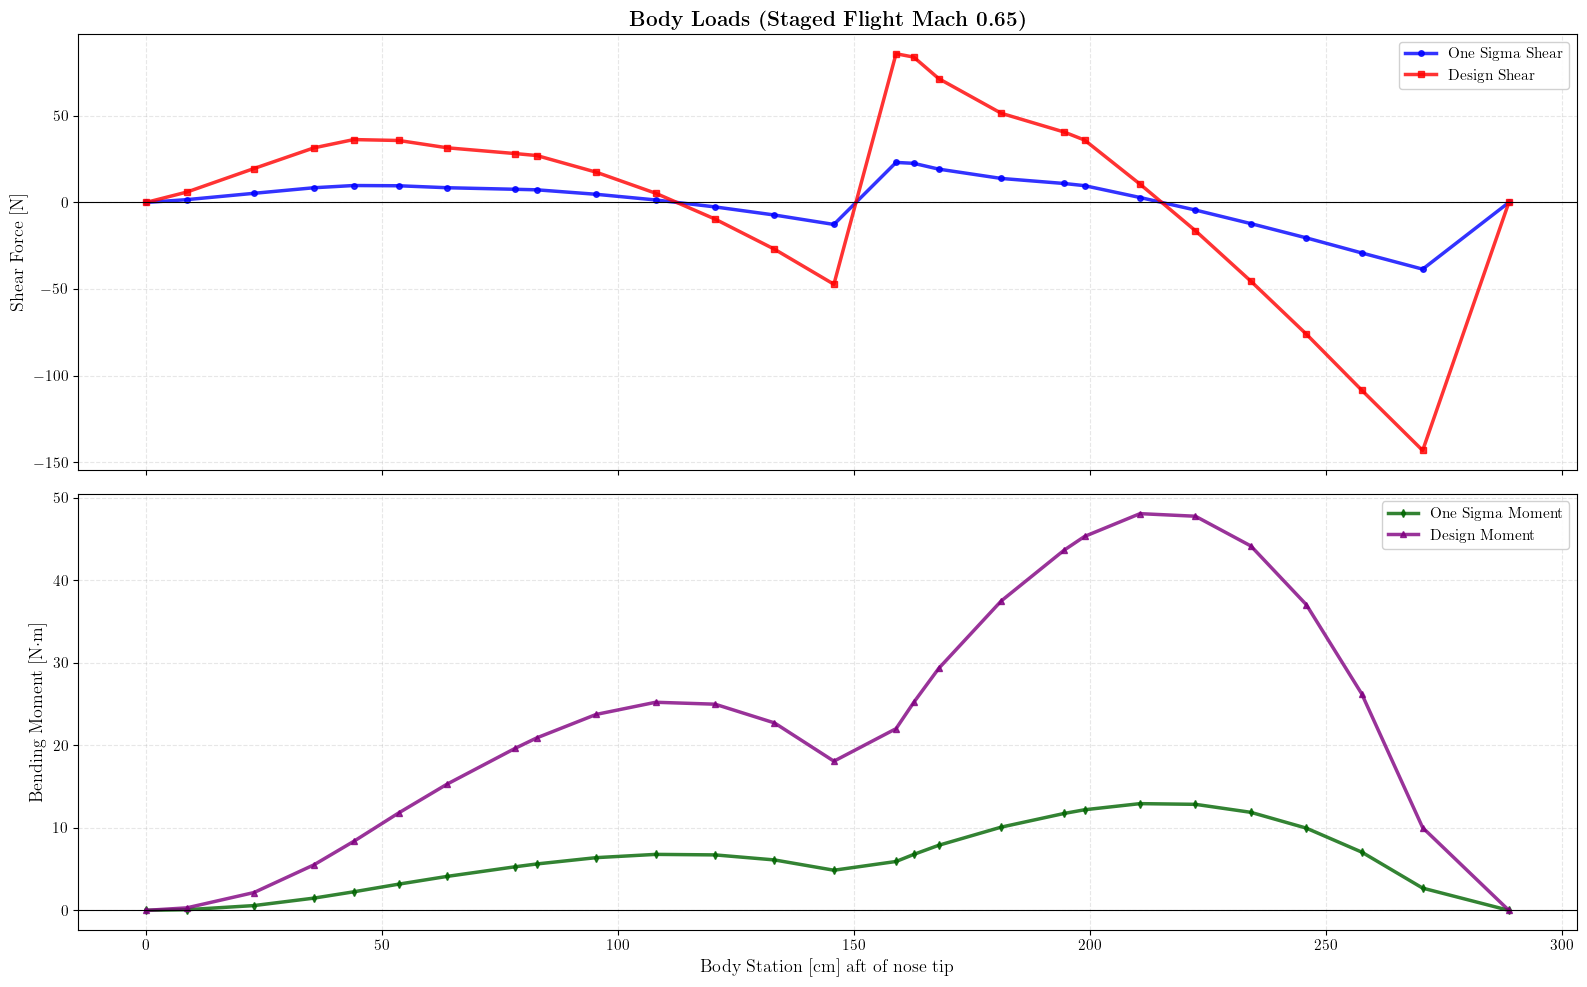

In [50]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Shear forces
ax1.plot(body_df_065['station_cm'], body_df_065['one_sigma_shear_N'], 
         'b-', linewidth=2.5, marker='o', markersize=4, 
         label=r'One Sigma Shear', alpha=0.8)
ax1.plot(body_df_065['station_cm'], body_df_065['design_shear_N'], 
         'r-', linewidth=2.5, marker='s', markersize=4, 
         label=r'Design Shear', alpha=0.8)
ax1.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax1.set_ylabel(r'Shear Force [N]', fontsize=13)
ax1.set_title(r'\textbf{Body Loads (Staged Flight Mach 0.65)}', fontsize=15)
ax1.legend(loc='best', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3, linestyle='--')


# Bending moment
ax2.plot(body_df_065['station_cm'], body_df_065['one_sigma_moment_Nm'], 
         'darkgreen', linewidth=2.5, marker='d', markersize=4, 
         label=r'One Sigma Moment', alpha=0.8)
ax2.plot(body_df_065['station_cm'], body_df_065['design_moment_Nm'], 
         'purple', linewidth=2.5, marker='^', markersize=4, 
         label=r'Design Moment', alpha=0.8)
ax2.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax2.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax2.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax2.legend(loc='best', fontsize=11, framealpha=0.9)
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('body_loads_combined_mach065.pdf', dpi=300, bbox_inches='tight')

In [54]:
axial_df_065

,station_in,force_lb,station_cm,force_N
0,3.3870,-4.945068,8.602980,-21.996751
1,9.0000,-6.374117,22.860000,-28.353473
2,14.0000,-8.160427,35.560000,-36.299375
3,17.3220,-16.566595,43.997880,-73.691857
4,21.0830,-31.711337,53.550820,-141.059004
5,25.1380,-74.414434,63.850520,-331.011772
6,30.7990,-92.954351,78.229460,-413.481403
7,32.6000,-97.671313,82.804000,-434.463489
8,37.5572,-130.090637,95.395288,-578.671772
9,42.5144,-162.173713,107.986576,-721.384356


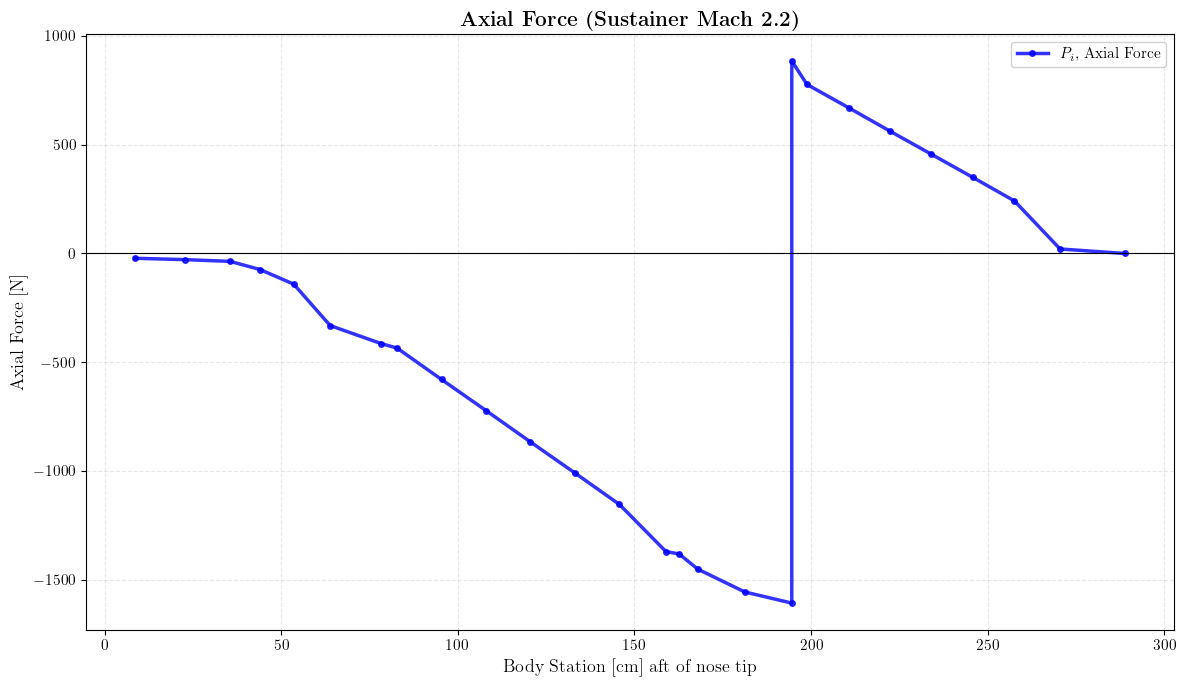

In [55]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(axial_df_065['station_cm'], axial_df_065['force_N'], 
        'b-', linewidth=2.5, marker='o', markersize=4, 
        label=r'$P_i$, Axial Force', alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force (Sustainer Mach 2.2)}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('axial_force_mach065.pdf', dpi=300, bbox_inches='tight')

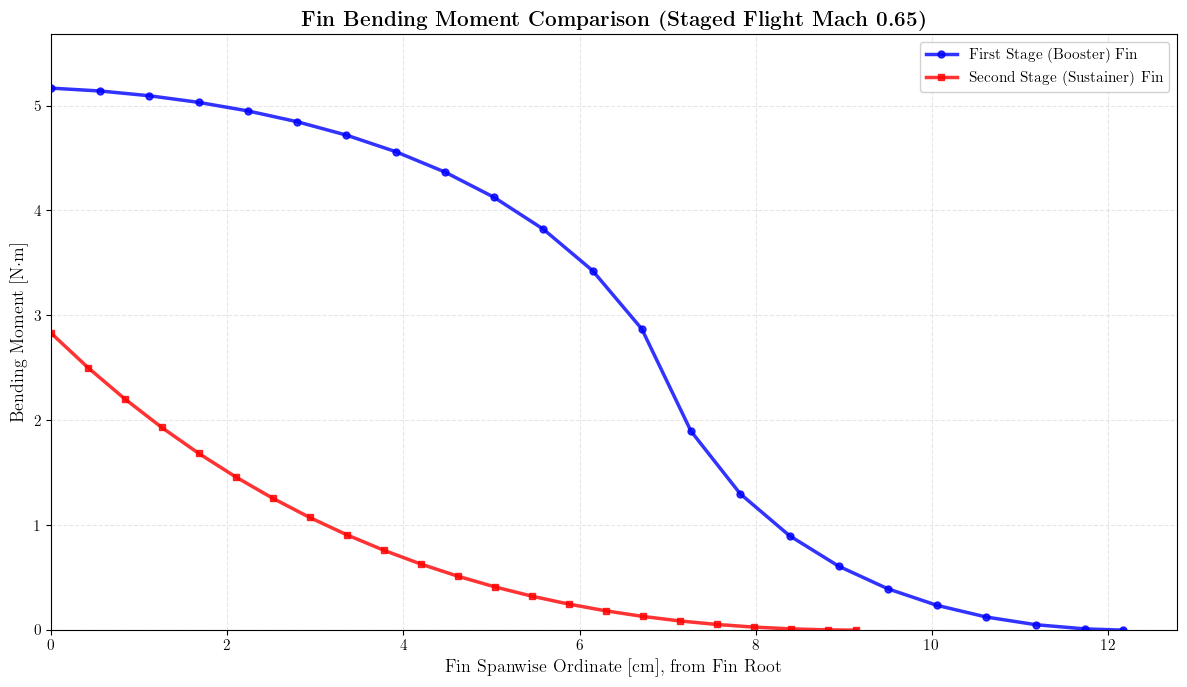

In [51]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(axial_df_065['station_cm'], axial_df_065['force_N'], 
        'b-', linewidth=2.5, marker='o', markersize=4, 
        label=r'$P_i$, Axial Force', alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force (Staged Flight Mach 0.65)}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('axial_force_mach065.pdf', dpi=300, bbox_inches='tight')
plt.close()

# ============ PLOT 3: Fin Bending Moment Comparison ============
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(fin1_df_065['span_cm'], fin1_df_065['moment_Nm'], 
        'b-', linewidth=2.5, marker='o', markersize=5, 
        label=r'First Stage (Booster) Fin', alpha=0.8)
ax.plot(fin2_df_065['span_cm'], fin2_df_065['moment_Nm'], 
        'r-', linewidth=2.5, marker='s', markersize=5, 
        label=r'Second Stage (Sustainer) Fin', alpha=0.8)
ax.set_xlabel(r'Fin Spanwise Ordinate [cm], from Fin Root', fontsize=13)
ax.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Fin Bending Moment Comparison (Staged Flight Mach 0.65)}', fontsize=15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, max(max(fin1_df_065['span_cm']), max(fin2_df_065['span_cm'])) * 1.05)
ax.set_ylim(0, max(max(fin1_df_065['moment_Nm']), max(fin2_df_065['moment_Nm'])) * 1.1)
plt.tight_layout()
plt.savefig('fin_bending_comparison_mach065.pdf', dpi=300, bbox_inches='tight')

In [52]:
# ============ Summary Statistics ============
print("\n" + "="*80)
print("SUMMARY STATISTICS - MACH 0.65")
print("="*80)

print("\nBody Loads:")
print(f"  Max One Sigma Shear: {body_df_065['one_sigma_shear_N'].max():.2f} N")
print(f"  Max Design Shear: {body_df_065['design_shear_N'].max():.2f} N")
print(f"  Max One Sigma Moment: {body_df_065['one_sigma_moment_Nm'].max():.2f} N·m")
print(f"  Max Design Moment: {body_df_065['design_moment_Nm'].max():.2f} N·m")

print("\nAxial Force:")
print(f"  Max Compression: {axial_df_065['force_N'].min():.2f} N")
print(f"  Max Tension: {axial_df_065['force_N'].max():.2f} N")

print("\nBooster Fin:")
print(f"  Max Moment: {fin1_df_065['moment_Nm'].max():.3f} N·m")
print(f"  Span: {fin1_df_065['span_cm'].max():.2f} cm")

print("\nSustainer Fin:")
print(f"  Max Moment: {fin2_df_065['moment_Nm'].max():.3f} N·m")
print(f"  Span: {fin2_df_065['span_cm'].max():.2f} cm")


SUMMARY STATISTICS - MACH 0.65

Body Loads:
  Max One Sigma Shear: 23.09 N
  Max Design Shear: 85.84 N
  Max One Sigma Moment: 12.93 N·m
  Max Design Moment: 48.07 N·m

Axial Force:
  Max Compression: -1605.71 N
  Max Tension: 883.96 N

Booster Fin:
  Max Moment: 5.166 N·m
  Span: 12.17 cm

Sustainer Fin:
  Max Moment: 2.833 N·m
  Span: 9.14 cm


# Mach 1.123

In [39]:
# Body Loads Data
body_data_112 = """0	0	0	0	0
3.387	0.820391725	1.034463458	3.049332205	3.845020181
9	1.588627191	7.799946315	5.904803656	28.99179353
14	2.283126792	17.66881259	8.486204631	65.67360158
17.322	3.056580061	26.53615162	11.36107025	98.63281075
21.083	3.847032875	39.63922476	14.29912185	147.3359141
25.138	5.384897478	58.7315173	20.01524492	218.3004799
30.799	5.679671271	90.31220869	21.11089617	335.6834524
32.6	5.681803252	100.5631079	21.11882058	373.7852471
37.5572	5.242894882	128.0163651	19.48743232	475.8268678
42.5144	4.150057458	151.6691446	15.42544065	563.7424088
47.4716	2.380384014	168.2307972	8.847702159	625.3007829
52.4288	-0.029416057	174.4293142	-0.109337195	648.3401884
57.386	-3.129854576	166.9740464	-11.63342592	620.6295381
62.571	12.43727515	184.5325787	46.22838399	685.8932364
64.048	12.10466924	202.6666244	44.99211367	753.2960731
66.134	9.94148744	225.7329648	36.95173526	839.0318657
71.349	6.355269123	268.5194763	23.62204082	998.0659995
76.6	4.340913584	296.747817	16.13483802	1102.988545
78.3	3.460941086	303.3984626	12.86404872	1127.708478
82.9245	-0.031345313	311.5096152	-0.116508088	1157.857001
87.549	-3.780171221	302.8739832	-14.05060229	1125.759028
92.1735	-7.934297482	275.9682726	-29.49116636	1025.752596
96.798	-12.33208717	229.2848718	-45.83740843	852.2340274
101.4225	-17.05435874	161.5136092	-63.38972443	600.333518
106.506	-22.21766736	61.90157834	-82.58134079	230.0833501
113.697	0	0	0	0"""

body_df_112 = pd.read_csv(StringIO(body_data_112), sep='\t', header=None, 
                           names=['station_in', 'one_sigma_shear_lb', 'one_sigma_moment_inlb', 
                                  'design_shear_lb', 'design_moment_inlb'])

# Add SI unit conversions
body_df_112['station_cm'] = body_df_112['station_in'] * IN_TO_CM
body_df_112['one_sigma_shear_N'] = body_df_112['one_sigma_shear_lb'] * LB_TO_N
body_df_112['one_sigma_moment_Nm'] = body_df_112['one_sigma_moment_inlb'] * INLB_TO_NM
body_df_112['design_shear_N'] = body_df_112['design_shear_lb'] * LB_TO_N
body_df_112['design_moment_Nm'] = body_df_112['design_moment_inlb'] * INLB_TO_NM

# Axial Force Data
axial_data_112 = """3.387	-2.127436512
9	-2.742232875
14	-3.510728328
17.322	-7.127177521
21.083	-13.64265472
25.138	-32.01411596
30.799	-39.99024414
32.6	-42.01954638
37.5572	-55.96678657
42.5144	-69.7693688
47.4716	-83.71660899
52.4288	-97.51919122
57.386	-111.4664314
62.571	-132.3930539
64.048	-133.4901919
66.134	-140.243749
71.349	-150.3334296
76.6	-155.2973952
76.6012	62.92260482
78.3	55.4870828
82.9245	48.19621875
87.549	40.76069674
92.1735	33.46983269
96.798	26.17896864
101.4225	18.74344662
106.506	2.003383526
113.697	0"""

axial_df_112 = pd.read_csv(StringIO(axial_data_112), sep='\t', header=None,
                            names=['station_in', 'force_lb'])
axial_df_112['station_cm'] = axial_df_112['station_in'] * IN_TO_CM
axial_df_112['force_N'] = axial_df_112['force_lb'] * LB_TO_N

# Second Stage Fins (Sustainer)
fin2_data_112 = """0	31.80503128
0.165227273	28.08294135
0.330454545	24.69892266
0.495681818	21.62312418
0.660909091	18.83058079
0.826136364	16.29990131
0.991363636	14.01237381
1.156590909	11.951339
1.321818182	10.10174087
1.487045455	8.449797867
1.652272727	6.982757828
1.8175	5.688712318
1.982727273	4.556453934
2.147954545	3.575365143
2.313181818	2.735330633
2.478409091	2.026667417
2.643636364	1.440068517
2.808863636	0.966557155
2.974090909	0.597449141
3.139318182	0.324321735
3.304545455	0.138987662
3.469772727	0.033473265
3.59865	0.001572511"""

fin2_df_112 = pd.read_csv(StringIO(fin2_data_112), sep='\t', header=None,
                           names=['span_in', 'moment_inlb'])
fin2_df_112['span_cm'] = fin2_df_112['span_in'] * IN_TO_CM
fin2_df_112['moment_Nm'] = fin2_df_112['moment_inlb'] * INLB_TO_NM

# First Stage Fins (Booster)
fin1_data_112 = """0	231.491605
0.22	242.8771659
0.44	247.9053336
0.66	246.6820357
0.88	238.6893885
1.1	222.4341417
1.32	193.6212201
1.54	135.514062
1.76	100.721121
1.98	77.47040934
2.2	60.06529546
2.42	46.47937637
2.64	35.66379884
2.86	26.97978098
3.08	19.99903906
3.3	14.4151557
3.52	9.998236624
3.74	6.56936077
3.96	3.985128576
4.18	2.127795981
4.4	0.898697521
4.62	0.213705208
4.7916	0.009952224"""

fin1_df_112 = pd.read_csv(StringIO(fin1_data_112), sep='\t', header=None,
                           names=['span_in', 'moment_inlb'])
fin1_df_112['span_cm'] = fin1_df_112['span_in'] * IN_TO_CM
fin1_df_112['moment_Nm'] = fin1_df_112['moment_inlb'] * INLB_TO_NM

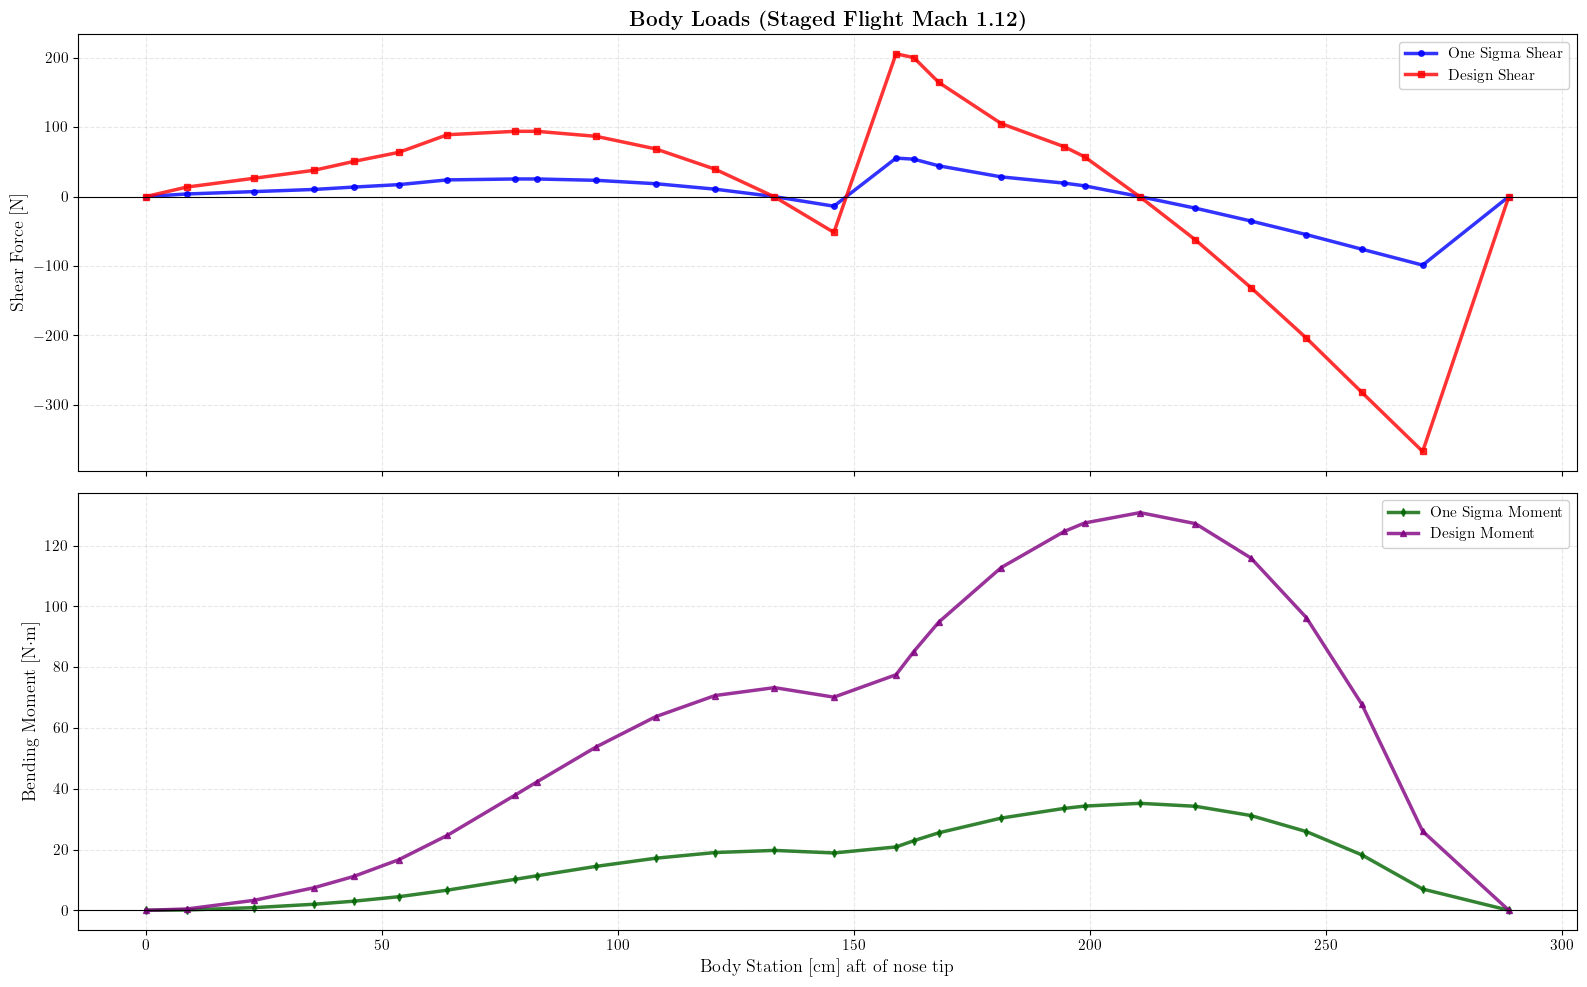

In [40]:
# ============ PLOT 1: Combined Body Loads ============
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Shear forces
ax1.plot(body_df_112['station_cm'], body_df_112['one_sigma_shear_N'], 
         'b-', linewidth=2.5, marker='o', markersize=4, 
         label=r'One Sigma Shear', alpha=0.8)
ax1.plot(body_df_112['station_cm'], body_df_112['design_shear_N'], 
         'r-', linewidth=2.5, marker='s', markersize=4, 
         label=r'Design Shear', alpha=0.8)
ax1.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax1.set_ylabel(r'Shear Force [N]', fontsize=13)
ax1.set_title(r'\textbf{Body Loads (Staged Flight Mach 1.12)}', fontsize=15)
ax1.legend(loc='best', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3, linestyle='--')

# Bending moment
ax2.plot(body_df_112['station_cm'], body_df_112['one_sigma_moment_Nm'], 
         'darkgreen', linewidth=2.5, marker='d', markersize=4, 
         label=r'One Sigma Moment', alpha=0.8)
ax2.plot(body_df_112['station_cm'], body_df_112['design_moment_Nm'], 
         'purple', linewidth=2.5, marker='^', markersize=4, 
         label=r'Design Moment', alpha=0.8)
ax2.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax2.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax2.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax2.legend(loc='best', fontsize=11, framealpha=0.9)
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('body_loads_combined_mach112.pdf', dpi=300, bbox_inches='tight')

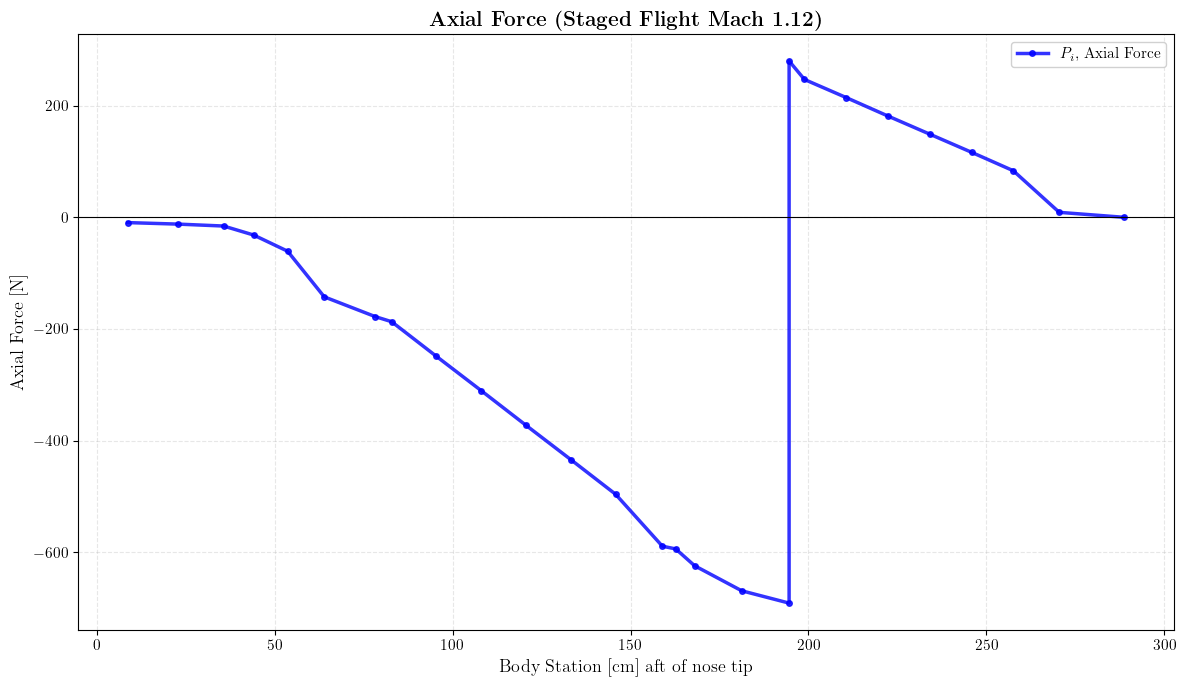

In [41]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(axial_df_112['station_cm'], axial_df_112['force_N'], 
        'b-', linewidth=2.5, marker='o', markersize=4, 
        label=r'$P_i$, Axial Force', alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force (Staged Flight Mach 1.12)}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('axial_force_mach112.pdf', dpi=300, bbox_inches='tight')

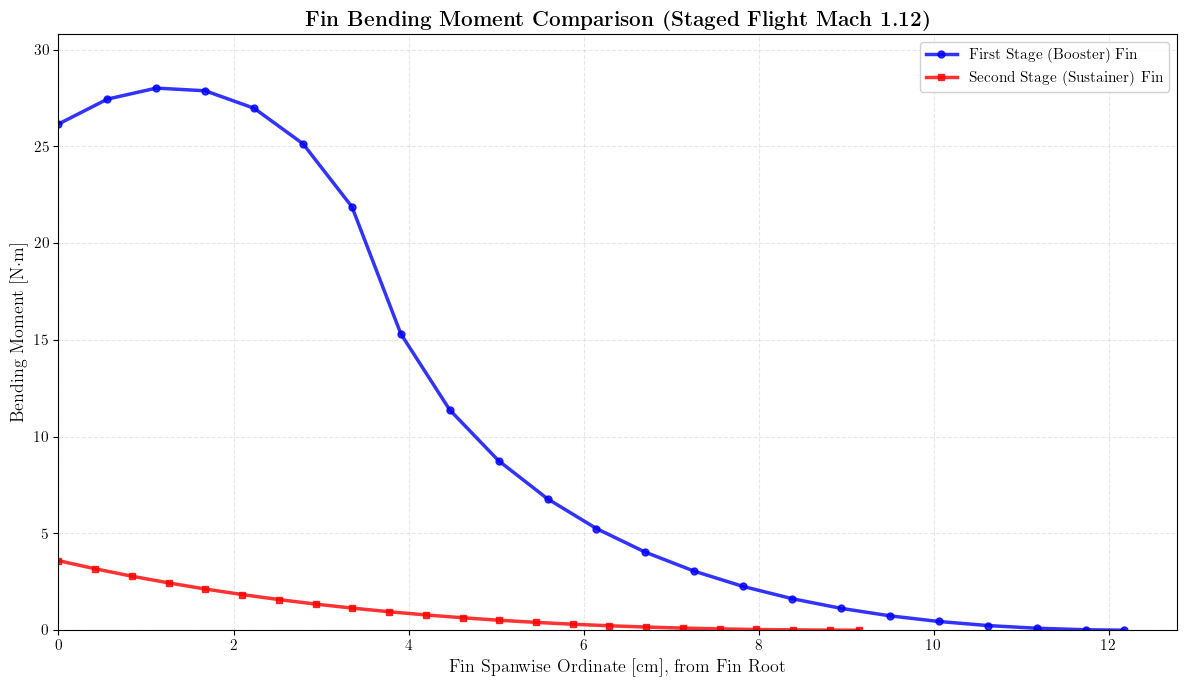

In [42]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(fin1_df_112['span_cm'], fin1_df_112['moment_Nm'], 
        'b-', linewidth=2.5, marker='o', markersize=5, 
        label=r'First Stage (Booster) Fin', alpha=0.8)
ax.plot(fin2_df_112['span_cm'], fin2_df_112['moment_Nm'], 
        'r-', linewidth=2.5, marker='s', markersize=5, 
        label=r'Second Stage (Sustainer) Fin', alpha=0.8)
ax.set_xlabel(r'Fin Spanwise Ordinate [cm], from Fin Root', fontsize=13)
ax.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Fin Bending Moment Comparison (Staged Flight Mach 1.12)}', fontsize=15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, max(max(fin1_df_112['span_cm']), max(fin2_df_112['span_cm'])) * 1.05)
ax.set_ylim(0, max(max(fin1_df_112['moment_Nm']), max(fin2_df_112['moment_Nm'])) * 1.1)
plt.tight_layout()
plt.savefig('fin_bending_comparison_mach112.pdf', dpi=300, bbox_inches='tight')

# Mach 2.2

In [43]:
# Body Loads Data
body_data_22 = """0	0	0	0	0
3.387	0.970494438	1.903753669	3.607252309	7.076104253
9	3.237753688	13.98904206	12.03447852	51.99618083
14	5.403230261	36.42918582	20.08338645	135.4044491
17.322	6.399333505	55.93348882	23.7858247	207.9004257
21.083	6.2969521	80.25812117	23.40528098	298.3131914
25.138	3.793831356	101.2306623	14.10137595	376.2664948
30.799	2.22214223	118.5965004	8.259529761	440.813964
32.6	1.729681232	122.1798485	6.429090552	454.1329899
37.5572	-0.153232185	126.3094725	-0.569552108	469.482481
42.5144	-2.380467925	120.2466692	-8.848014049	446.947513
47.4716	-4.992818571	102.188453	-18.55791813	379.8265284
52.4288	-8.056928927	70.06538961	-29.9469779	260.4276013
57.386	-11.51470273	21.77718413	-42.79925408	80.94409889
62.571	0	0	0	0"""

body_df_22 = pd.read_csv(StringIO(body_data_22), sep='\t', header=None, 
                          names=['station_in', 'one_sigma_shear_lb', 'one_sigma_moment_inlb', 
                                 'design_shear_lb', 'design_moment_inlb'])

# Add SI unit conversions
body_df_22['station_cm'] = body_df_22['station_in'] * IN_TO_CM
body_df_22['one_sigma_shear_N'] = body_df_22['one_sigma_shear_lb'] * LB_TO_N
body_df_22['one_sigma_moment_Nm'] = body_df_22['one_sigma_moment_inlb'] * INLB_TO_NM
body_df_22['design_shear_N'] = body_df_22['design_shear_lb'] * LB_TO_N
body_df_22['design_moment_Nm'] = body_df_22['design_moment_inlb'] * INLB_TO_NM

# Axial Force Data
axial_data_22 = """3.387	-2.420155736
9	-3.119543443
14	-3.993778077
17.322	-8.107823413
21.083	-15.51978115
25.138	-36.41901695
30.799	-45.49260023
30.8002	53.89739977
32.6	46.3330132
37.5572	38.93318844
42.5144	31.53336368
47.4716	23.96897711
52.4288	16.40459054
57.386	2.308518926
62.571	0"""

axial_df_22 = pd.read_csv(StringIO(axial_data_22), sep='\t', header=None,
                           names=['station_in', 'force_lb'])
axial_df_22['station_cm'] = axial_df_22['station_in'] * IN_TO_CM
axial_df_22['force_N'] = axial_df_22['force_lb'] * LB_TO_N

# First Stage Fins (Sustainer - note: only sustainer fins for Mach 2.2)
fin1_data_22 = """0	62.56754606
0.165227273	55.47401562
0.330454545	48.98826357
0.495681818	43.06025418
0.660909091	37.64833649
0.826136364	32.71694496
0.991363636	28.23503131
1.156590909	24.17496549
1.321818182	20.51174729
1.487045455	17.22242873
1.652272727	14.28568324
1.8175	11.68147872
1.982727273	9.390825815
2.147954545	7.395581423
2.313181818	5.678293306
2.478409091	4.222075804
2.643636364	3.010509323
2.808863636	2.027558211
2.974090909	1.25750301
3.139318182	0.684884056
3.304545455	0.294454125
3.469772727	0.071138343
3.59865	0.003349929"""

fin1_df_22 = pd.read_csv(StringIO(fin1_data_22), sep='\t', header=None,
                          names=['span_in', 'moment_inlb'])
fin1_df_22['span_cm'] = fin1_df_22['span_in'] * IN_TO_CM
fin1_df_22['moment_Nm'] = fin1_df_22['moment_inlb'] * INLB_TO_NM


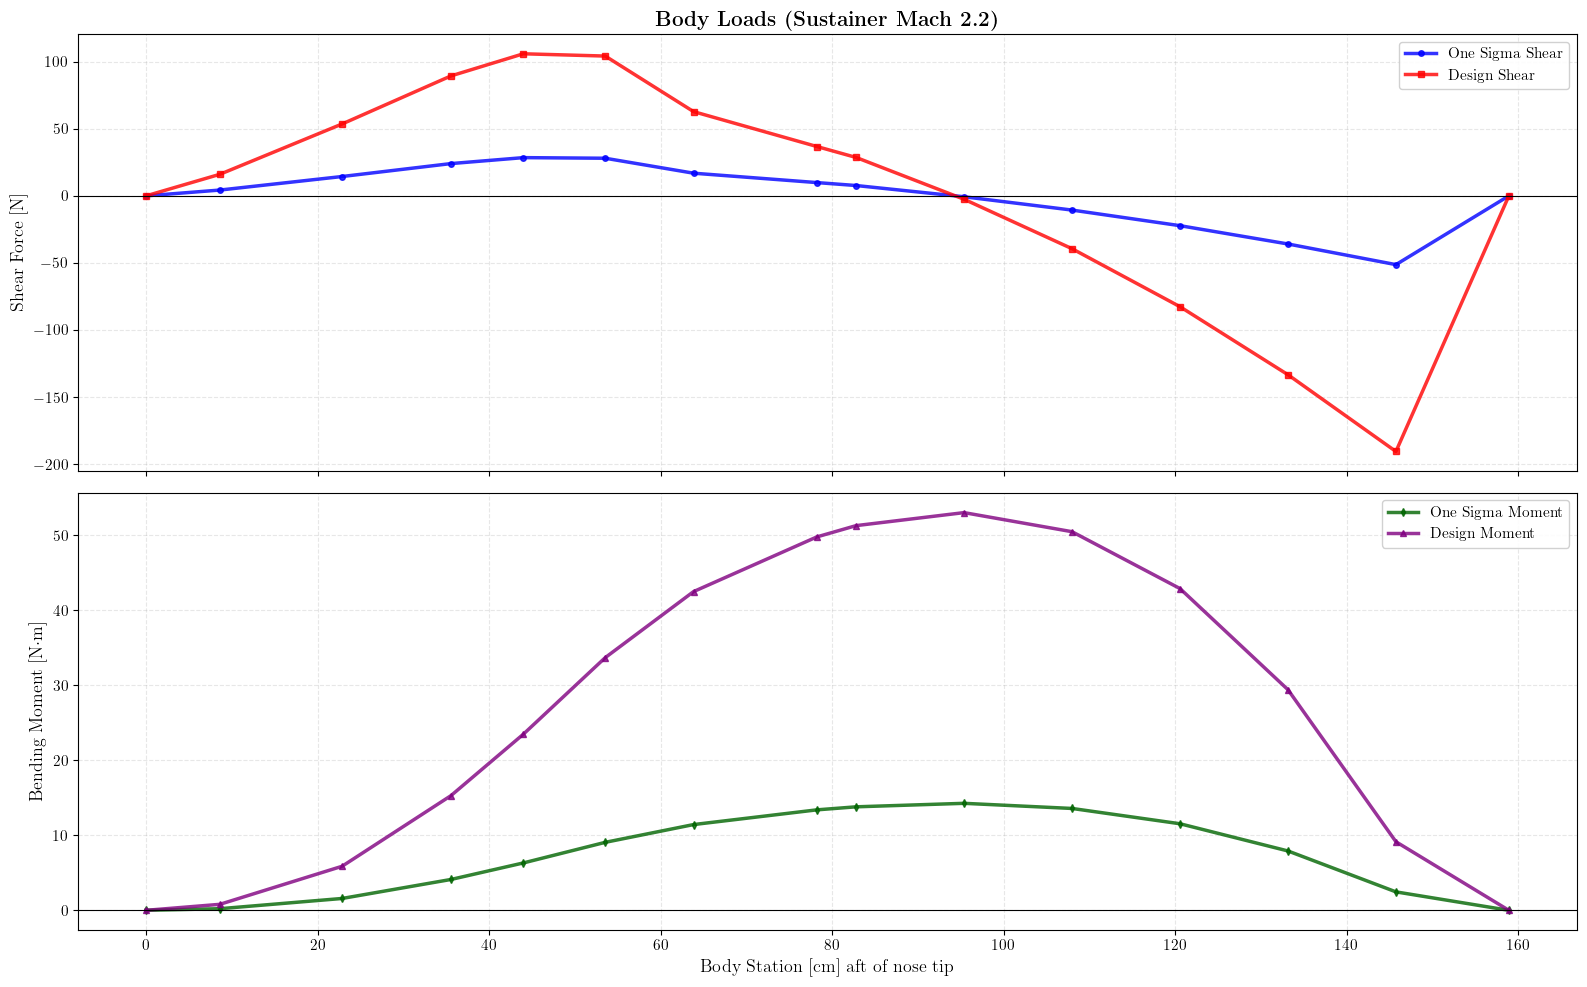

In [44]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Shear forces
ax1.plot(body_df_22['station_cm'], body_df_22['one_sigma_shear_N'], 
         'b-', linewidth=2.5, marker='o', markersize=4, 
         label=r'One Sigma Shear', alpha=0.8)
ax1.plot(body_df_22['station_cm'], body_df_22['design_shear_N'], 
         'r-', linewidth=2.5, marker='s', markersize=4, 
         label=r'Design Shear', alpha=0.8)
ax1.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax1.set_ylabel(r'Shear Force [N]', fontsize=13)
ax1.set_title(r'\textbf{Body Loads (Sustainer Mach 2.2)}', fontsize=15)
ax1.legend(loc='best', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3, linestyle='--')

# Bending moment
ax2.plot(body_df_22['station_cm'], body_df_22['one_sigma_moment_Nm'], 
         'darkgreen', linewidth=2.5, marker='d', markersize=4, 
         label=r'One Sigma Moment', alpha=0.8)
ax2.plot(body_df_22['station_cm'], body_df_22['design_moment_Nm'], 
         'purple', linewidth=2.5, marker='^', markersize=4, 
         label=r'Design Moment', alpha=0.8)
ax2.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax2.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax2.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax2.legend(loc='best', fontsize=11, framealpha=0.9)
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('body_loads_combined_mach22.pdf', dpi=300, bbox_inches='tight')

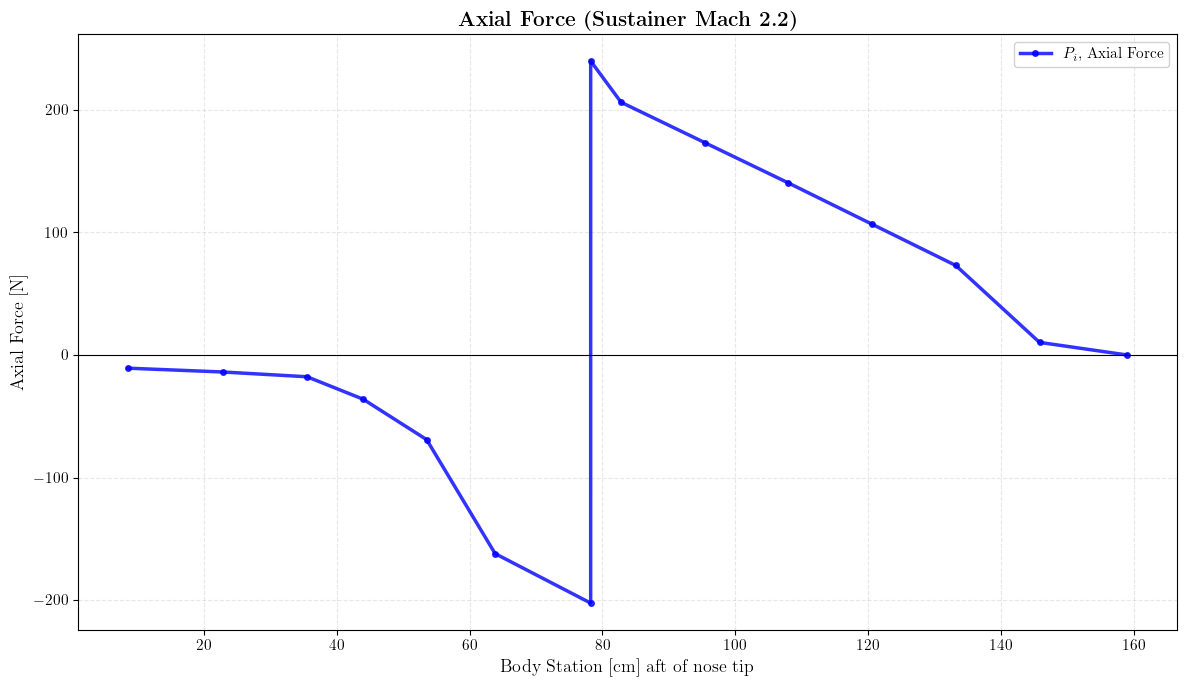

In [45]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(axial_df_22['station_cm'], axial_df_22['force_N'], 
        'b-', linewidth=2.5, marker='o', markersize=4, 
        label=r'$P_i$, Axial Force', alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force (Sustainer Mach 2.2)}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('axial_force_mach22.pdf', dpi=300, bbox_inches='tight')

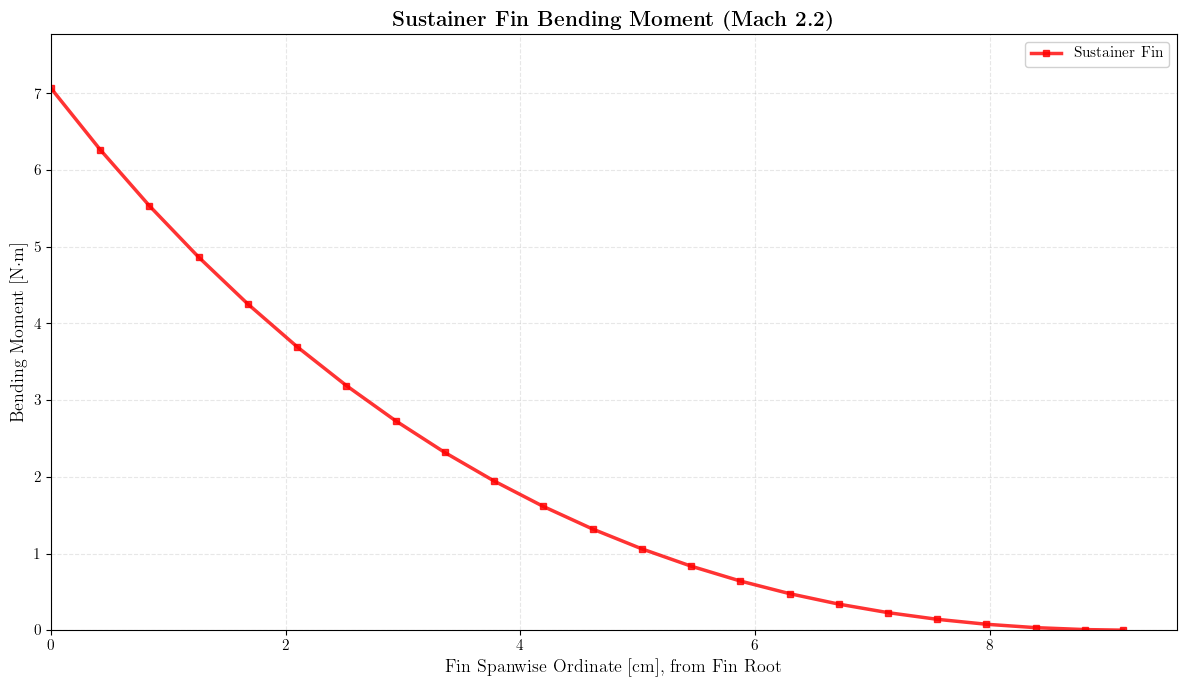

In [46]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(fin1_df_22['span_cm'], fin1_df_22['moment_Nm'], 
        'r-', linewidth=2.5, marker='s', markersize=5, 
        label=r'Sustainer Fin', alpha=0.8)
ax.set_xlabel(r'Fin Spanwise Ordinate [cm], from Fin Root', fontsize=13)
ax.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Sustainer Fin Bending Moment (Mach 2.2)}', fontsize=15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, max(fin1_df_22['span_cm']) * 1.05)
ax.set_ylim(0, max(fin1_df_22['moment_Nm']) * 1.1)
plt.tight_layout()
plt.savefig('fin_bending_mach22.pdf', dpi=300, bbox_inches='tight')

In [56]:

# Body Loads Data
body_data_10 = """0	0	0	0	0
3.387	0.614368107	1.018909606	2.283558448	3.787207723
9	1.629256443	7.406692995	6.055819423	27.53010154
14	2.517954267	18.08808524	9.359040085	67.23200538
17.322	2.972110058	27.18831554	11.04710182	101.0568533
21.083	3.03755053	38.57905245	11.29033896	143.3953361
25.138	2.70987365	50.50961049	10.0723895	187.740292
30.799	2.291177811	64.85962484	8.516129645	241.0781787
32.6	2.130637835	68.85621526	7.919415043	255.9331943
37.5572	0.900103106	76.60601553	3.345613206	284.7385989
42.5144	-0.731998285	77.25760039	-2.720780667	287.1604892
47.4716	-2.780597606	68.78620047	-10.33526494	255.6729548
52.4288	-5.275973671	49.05498868	-19.61038361	182.3335759
57.386	-8.192963515	15.90868675	-30.45260788	59.13135077
62.571	0	0	0	0"""

body_df_10 = pd.read_csv(StringIO(body_data_10), sep='\t', header=None, 
                          names=['station_in', 'one_sigma_shear_lb', 'one_sigma_moment_inlb', 
                                 'design_shear_lb', 'design_moment_inlb'])

# Add SI unit conversions
body_df_10['station_cm'] = body_df_10['station_in'] * IN_TO_CM
body_df_10['one_sigma_shear_N'] = body_df_10['one_sigma_shear_lb'] * LB_TO_N
body_df_10['one_sigma_moment_Nm'] = body_df_10['one_sigma_moment_inlb'] * INLB_TO_NM
body_df_10['design_shear_N'] = body_df_10['design_shear_lb'] * LB_TO_N
body_df_10['design_moment_Nm'] = body_df_10['design_moment_inlb'] * INLB_TO_NM

# Axial Force Data
axial_data_10 = """3.387	-5.284666629
9	-6.811853834
14	-8.720837842
17.322	-17.70429199
21.083	-33.88908752
25.138	-79.52478456
30.799	-99.33791562
30.8002	196.8720844
32.6	167.2578501
37.5572	138.002954
42.5144	108.7480579
47.4716	79.13382364
52.4288	49.51958938
57.386	5.040895819
62.571	0"""

axial_df_10 = pd.read_csv(StringIO(axial_data_10), sep='\t', header=None,
                           names=['station_in', 'force_lb'])
axial_df_10['station_cm'] = axial_df_10['station_in'] * IN_TO_CM
axial_df_10['force_N'] = axial_df_10['force_lb'] * LB_TO_N

# Sustainer Fins
fin1_data_10 = """0	31.01192846
0.165227273	27.37926879
0.330454545	24.08416553
0.495681818	21.09367984
0.660909091	18.38088394
0.826136364	15.92321364
0.991363636	13.70134525
1.156590909	11.69840926
1.321818182	9.899426888
1.487045455	8.290898212
1.652272727	6.860495498
1.8175	5.596831355
1.982727273	4.489280878
2.147954545	3.527843473
2.313181818	2.703034257
2.478409091	2.005797793
2.643636364	1.427438915
2.808863636	0.959566748
2.974090909	0.594049055
3.139318182	0.322974702
3.304545455	0.138622604
3.469772727	0.033435847
3.59865	0.001572576"""

fin1_df_10 = pd.read_csv(StringIO(fin1_data_10), sep='\t', header=None,
                          names=['span_in', 'moment_inlb'])
fin1_df_10['span_cm'] = fin1_df_10['span_in'] * IN_TO_CM
fin1_df_10['moment_Nm'] = fin1_df_10['moment_inlb'] * INLB_TO_NM


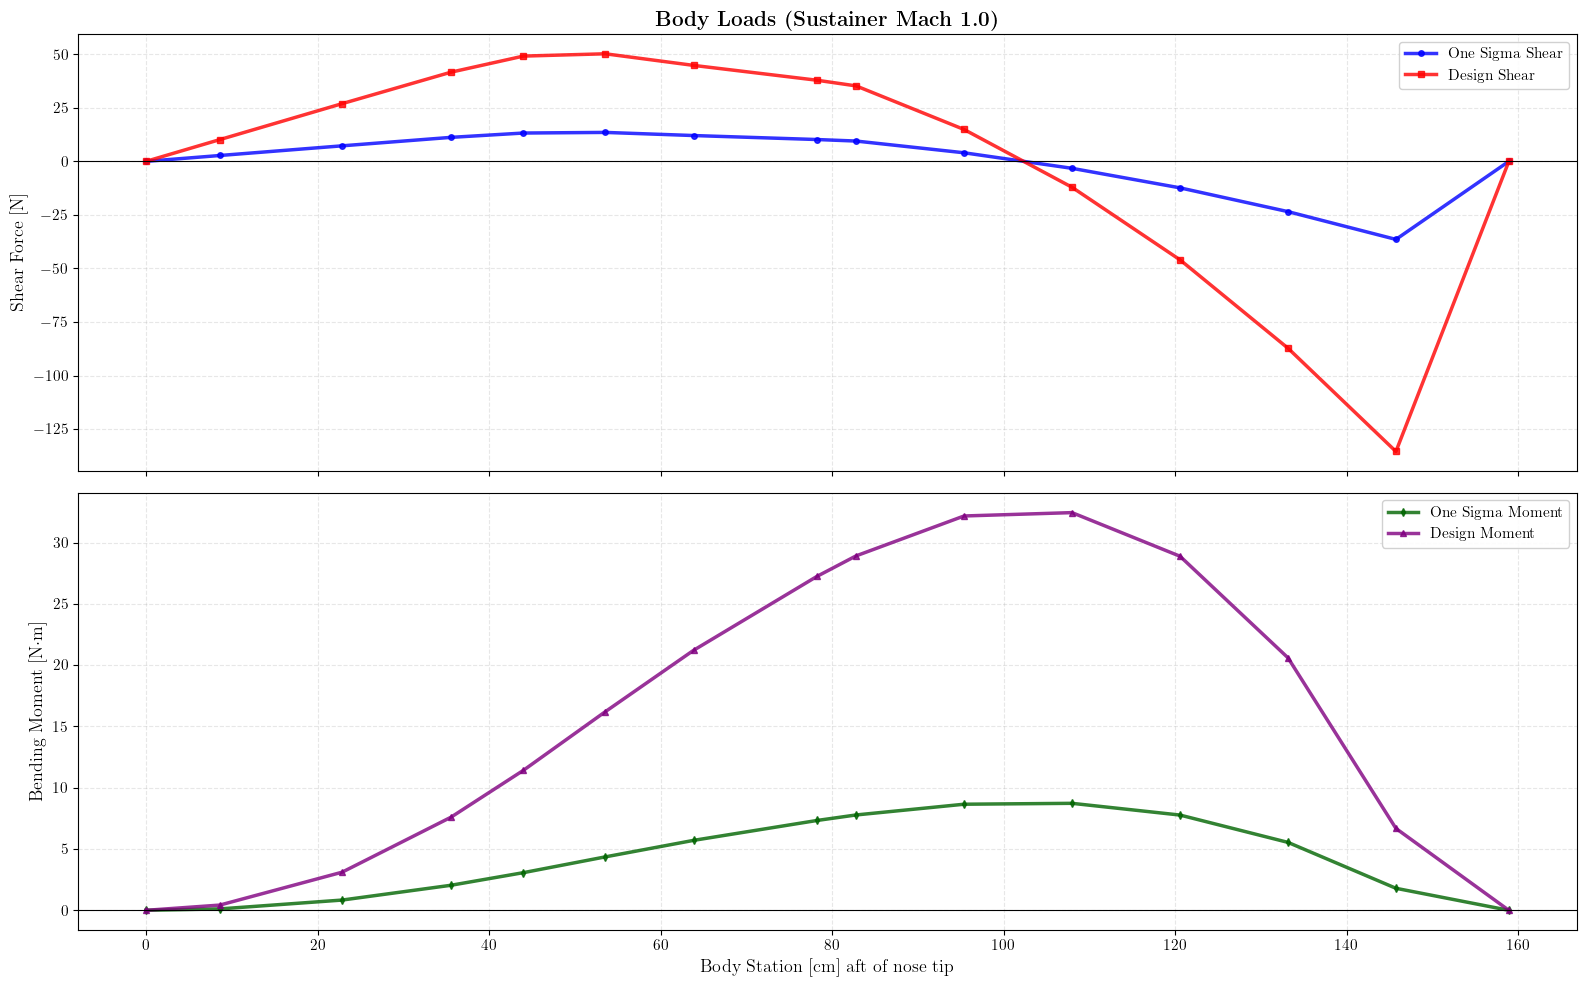

In [59]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Shear forces
ax1.plot(body_df_10['station_cm'], body_df_10['one_sigma_shear_N'], 
         'b-', linewidth=2.5, marker='o', markersize=4, 
         label=r'One Sigma Shear', alpha=0.8)
ax1.plot(body_df_10['station_cm'], body_df_10['design_shear_N'], 
         'r-', linewidth=2.5, marker='s', markersize=4, 
         label=r'Design Shear', alpha=0.8)
ax1.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax1.set_ylabel(r'Shear Force [N]', fontsize=13)
ax1.set_title(r'\textbf{Body Loads (Sustainer Mach 1.0)}', fontsize=15)
ax1.legend(loc='best', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3, linestyle='--')

# Bending moment
ax2.plot(body_df_10['station_cm'], body_df_10['one_sigma_moment_Nm'], 
         'darkgreen', linewidth=2.5, marker='d', markersize=4, 
         label=r'One Sigma Moment', alpha=0.8)
ax2.plot(body_df_10['station_cm'], body_df_10['design_moment_Nm'], 
         'purple', linewidth=2.5, marker='^', markersize=4, 
         label=r'Design Moment', alpha=0.8)
ax2.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax2.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax2.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax2.legend(loc='best', fontsize=11, framealpha=0.9)
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('body_loads_combined_mach10.pdf', dpi=300, bbox_inches='tight')

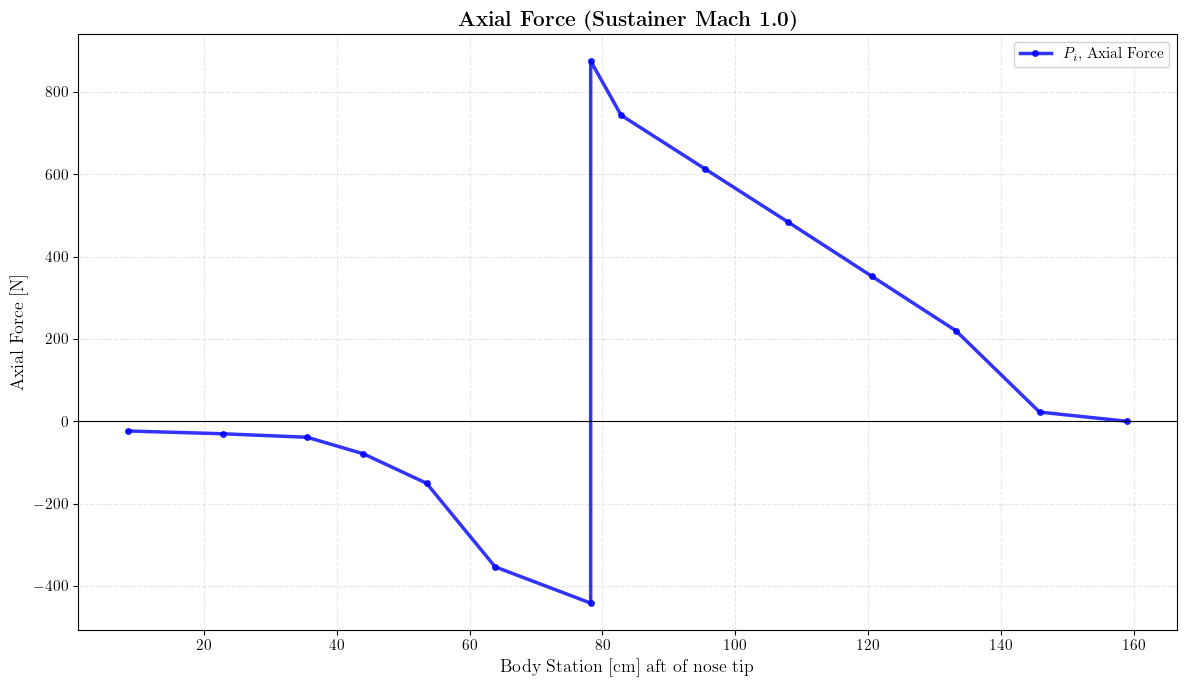

In [ ]:
# ============ PLOT 2: Axial Force ============
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(axial_df_10['station_cm'], axial_df_10['force_N'], 
        'b-', linewidth=2.5, marker='o', markersize=4, 
        label=r'$P_i$, Axial Force', alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force (Sustainer Mach 1.0)}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('axial_force_mach10.pdf', dpi=300, bbox_inches='tight')

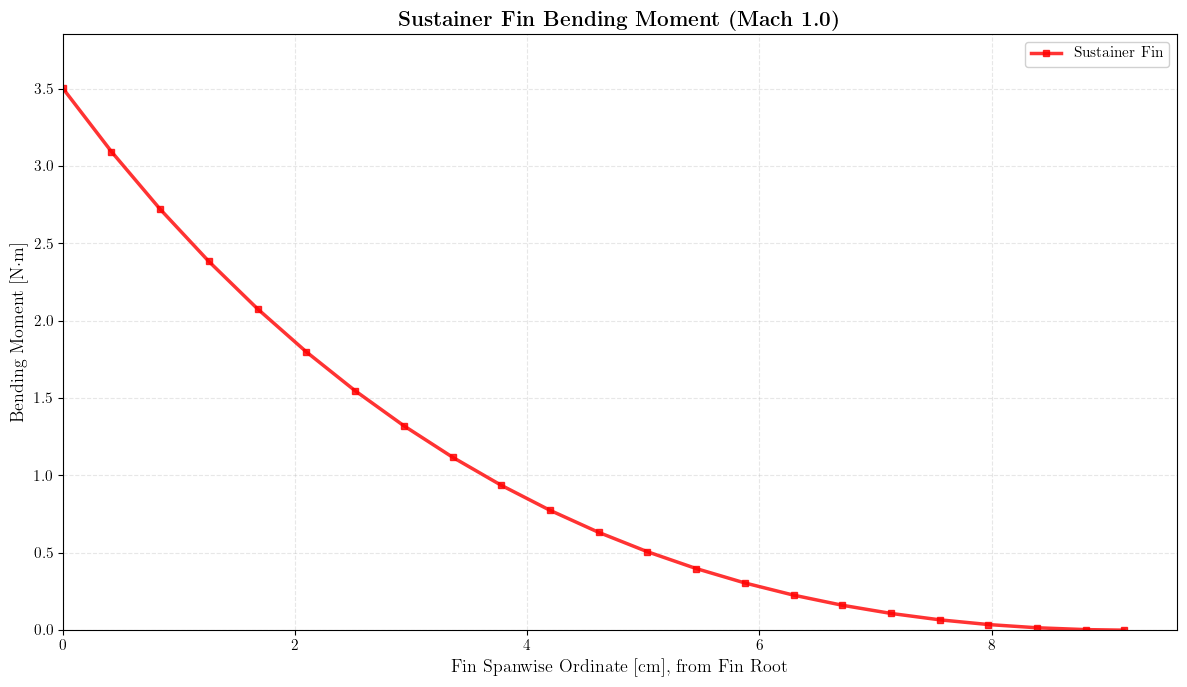

In [58]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(fin1_df_10['span_cm'], fin1_df_10['moment_Nm'], 
        'r-', linewidth=2.5, marker='s', markersize=5, 
        label=r'Sustainer Fin', alpha=0.8)
ax.set_xlabel(r'Fin Spanwise Ordinate [cm], from Fin Root', fontsize=13)
ax.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Sustainer Fin Bending Moment (Mach 1.0)}', fontsize=15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, max(fin1_df_10['span_cm']) * 1.05)
ax.set_ylim(0, max(fin1_df_10['moment_Nm']) * 1.1)
plt.tight_layout()
plt.savefig('fin_bending_mach10.pdf', dpi=300, bbox_inches='tight')

In [60]:
# Body Loads Data
body_data_055 = """0	0	0	0	0
3.387	0.863697132	1.571804438	3.210295034	5.842274792
9	2.551965413	11.33155758	9.485456869	42.11851779
14	4.028847693	28.31856206	14.97491339	105.2578917
17.322	4.67489903	42.72587946	17.37623593	158.8087694
21.083	4.643041324	60.35240086	17.25782332	224.3251779
25.138	3.957731364	78.11327065	14.71057952	290.3409489
30.799	3.338817322	98.99232241	12.41012419	367.9467597
32.6	3.1185545	104.8243288	11.59142442	389.6238737
37.5572	1.21381028	115.8859748	4.511638362	430.7391511
42.5144	-1.238679931	116.1444248	-4.604076921	431.6997897
47.4716	-4.258671756	102.8387808	-15.82915154	382.2437463
52.4288	-7.883763921	73.06598641	-29.30333705	271.5805861
57.386	-12.0823054	23.90153363	-44.90898904	88.84014069
62.571	0	0	0	0"""

body_df_055 = pd.read_csv(StringIO(body_data_055), sep='\t', header=None, 
                           names=['station_in', 'one_sigma_shear_lb', 'one_sigma_moment_inlb', 
                                  'design_shear_lb', 'design_moment_inlb'])

# Add SI unit conversions
body_df_055['station_cm'] = body_df_055['station_in'] * IN_TO_CM
body_df_055['one_sigma_shear_N'] = body_df_055['one_sigma_shear_lb'] * LB_TO_N
body_df_055['one_sigma_moment_Nm'] = body_df_055['one_sigma_moment_inlb'] * INLB_TO_NM
body_df_055['design_shear_N'] = body_df_055['design_shear_lb'] * LB_TO_N
body_df_055['design_moment_Nm'] = body_df_055['design_moment_inlb'] * INLB_TO_NM

# Axial Force Data
axial_data_055 = """0	0
3.387	-13.45873014
9	-17.31220545
14	-22.106419
17.322	-44.32983556
21.083	-82.96271585
25.138	-182.1612745
30.799	-220.75541
30.8002	505.103724
32.6	424.7613981
37.5572	330.23583
42.5144	244.0604109
47.4716	165.3319795
52.4288	94.73196646
57.386	8.114418921
62.571	0"""

axial_df_055 = pd.read_csv(StringIO(axial_data_055), sep='\t', header=None,
                            names=['station_in', 'force_lb'])
axial_df_055['station_cm'] = axial_df_055['station_in'] * IN_TO_CM
axial_df_055['force_N'] = axial_df_055['force_lb'] * LB_TO_N

# First Stage Fins (Sustainer)
fin1_data_055 = """0	42.1725963
0.165227273	37.21265252
0.330454545	32.71870264
0.495681818	28.64418265
0.660909091	24.95114105
0.826136364	21.60787681
0.991363636	18.58732927
1.156590909	15.86595083
1.321818182	13.42289927
1.487045455	11.2394472
1.652272727	9.298542593
1.8175	7.584476448
1.982727273	6.082627911
2.147954545	4.779266305
2.313181818	3.661395556
2.478409091	2.716630659
2.643636364	1.933098631
2.808863636	1.29935841
2.974090909	0.804335534
3.139318182	0.437268488
3.304545455	0.187664325
3.469772727	0.045261714
3.59865	0.002128676"""

fin1_df_055 = pd.read_csv(StringIO(fin1_data_055), sep='\t', header=None,
                           names=['span_in', 'moment_inlb'])
fin1_df_055['span_cm'] = fin1_df_055['span_in'] * IN_TO_CM
fin1_df_055['moment_Nm'] = fin1_df_055['moment_inlb'] * INLB_TO_NM

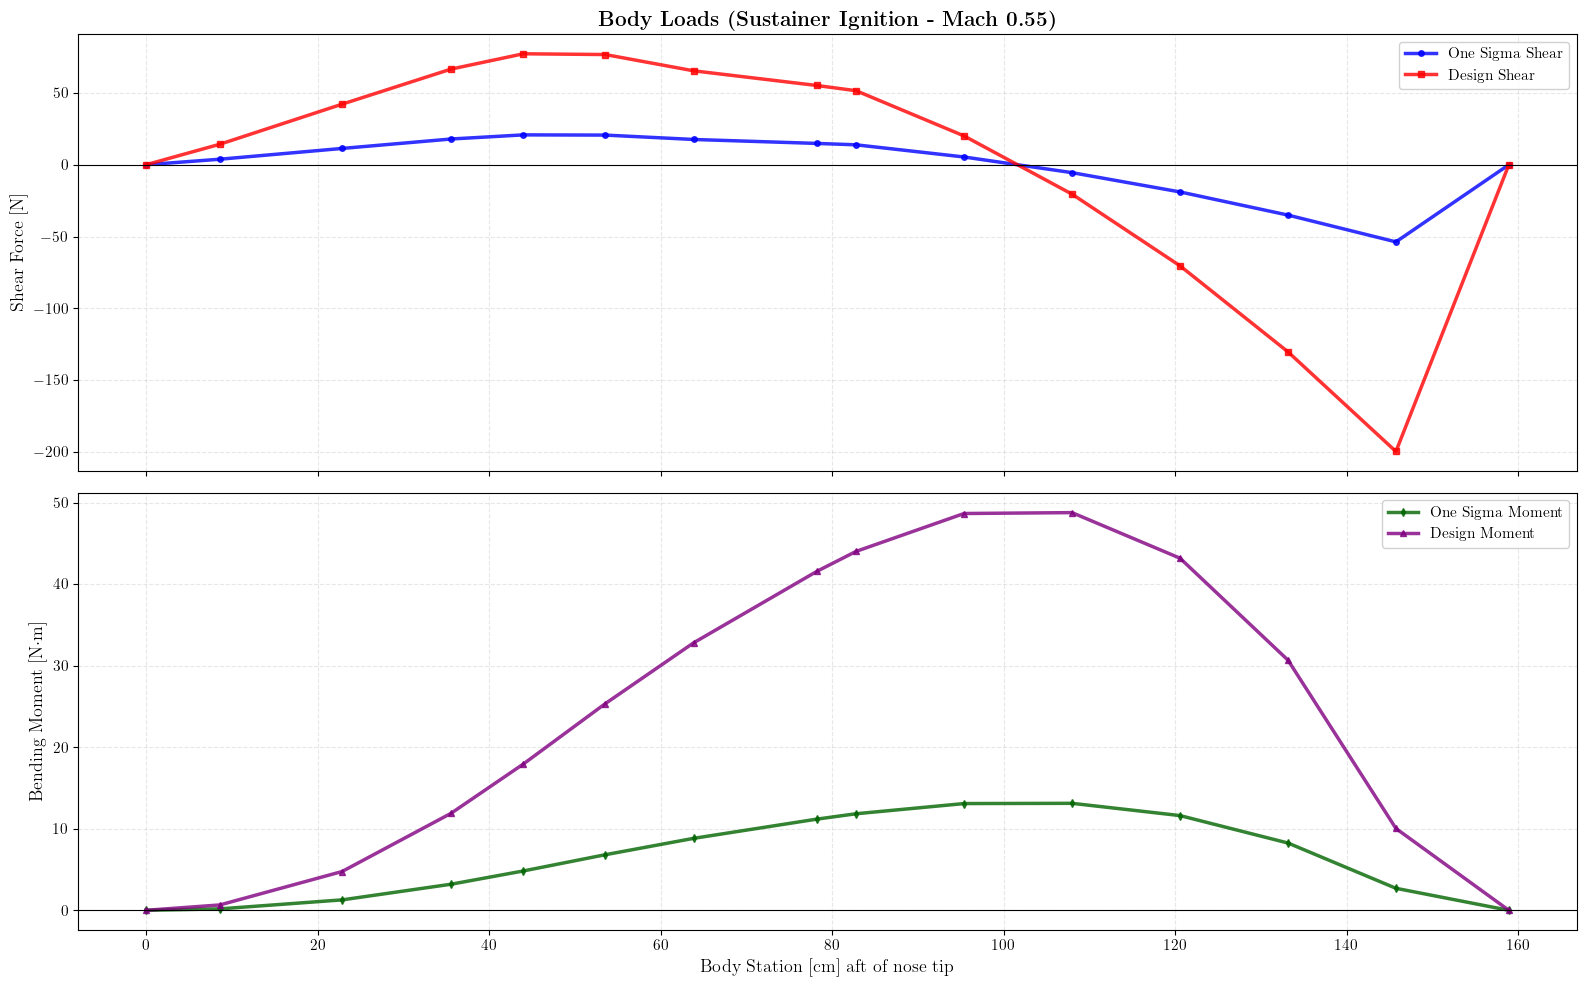

In [61]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Shear forces
ax1.plot(body_df_055['station_cm'], body_df_055['one_sigma_shear_N'], 
         'b-', linewidth=2.5, marker='o', markersize=4, 
         label=r'One Sigma Shear', alpha=0.8)
ax1.plot(body_df_055['station_cm'], body_df_055['design_shear_N'], 
         'r-', linewidth=2.5, marker='s', markersize=4, 
         label=r'Design Shear', alpha=0.8)
ax1.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax1.set_ylabel(r'Shear Force [N]', fontsize=13)
ax1.set_title(r'\textbf{Body Loads (Sustainer Ignition - Mach 0.55)}', fontsize=15)
ax1.legend(loc='best', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3, linestyle='--')

# Bending moment
ax2.plot(body_df_055['station_cm'], body_df_055['one_sigma_moment_Nm'], 
         'darkgreen', linewidth=2.5, marker='d', markersize=4, 
         label=r'One Sigma Moment', alpha=0.8)
ax2.plot(body_df_055['station_cm'], body_df_055['design_moment_Nm'], 
         'purple', linewidth=2.5, marker='^', markersize=4, 
         label=r'Design Moment', alpha=0.8)
ax2.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax2.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax2.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax2.legend(loc='best', fontsize=11, framealpha=0.9)
ax2.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('body_loads_combined_mach055_ignition.pdf', dpi=300, bbox_inches='tight')

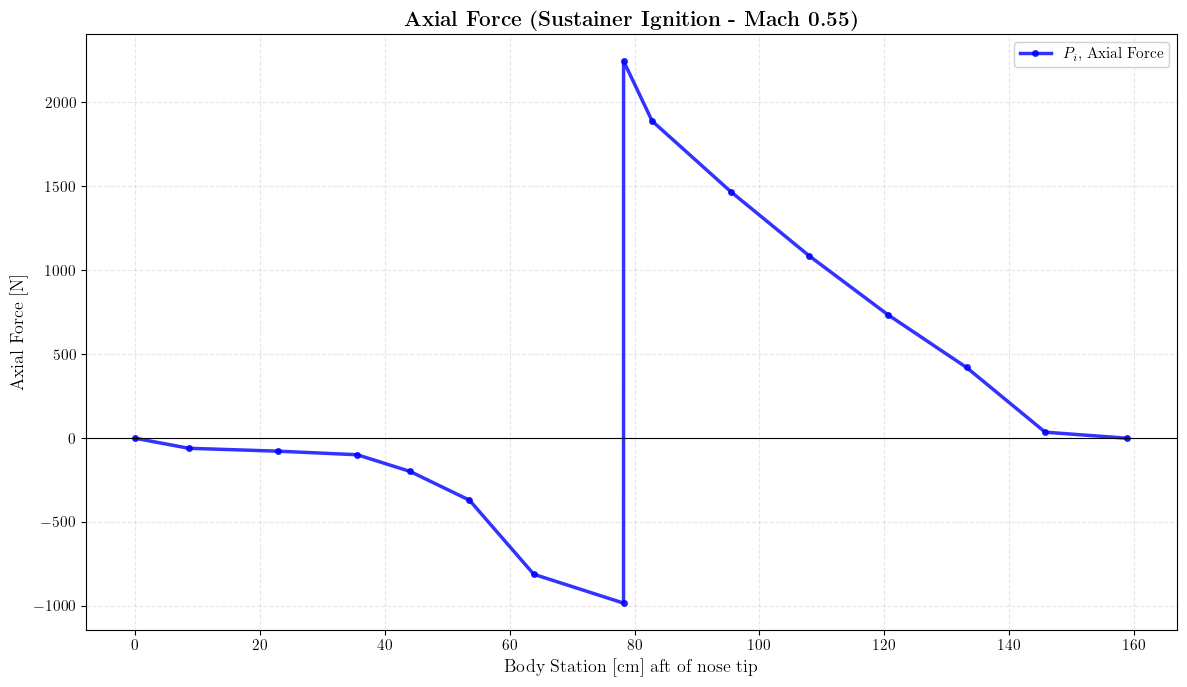

In [62]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(axial_df_055['station_cm'], axial_df_055['force_N'], 
        'b-', linewidth=2.5, marker='o', markersize=4, 
        label=r'$P_i$, Axial Force', alpha=0.8)
ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force (Sustainer Ignition - Mach 0.55)}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('axial_force_mach055_ignition.pdf', dpi=300, bbox_inches='tight')

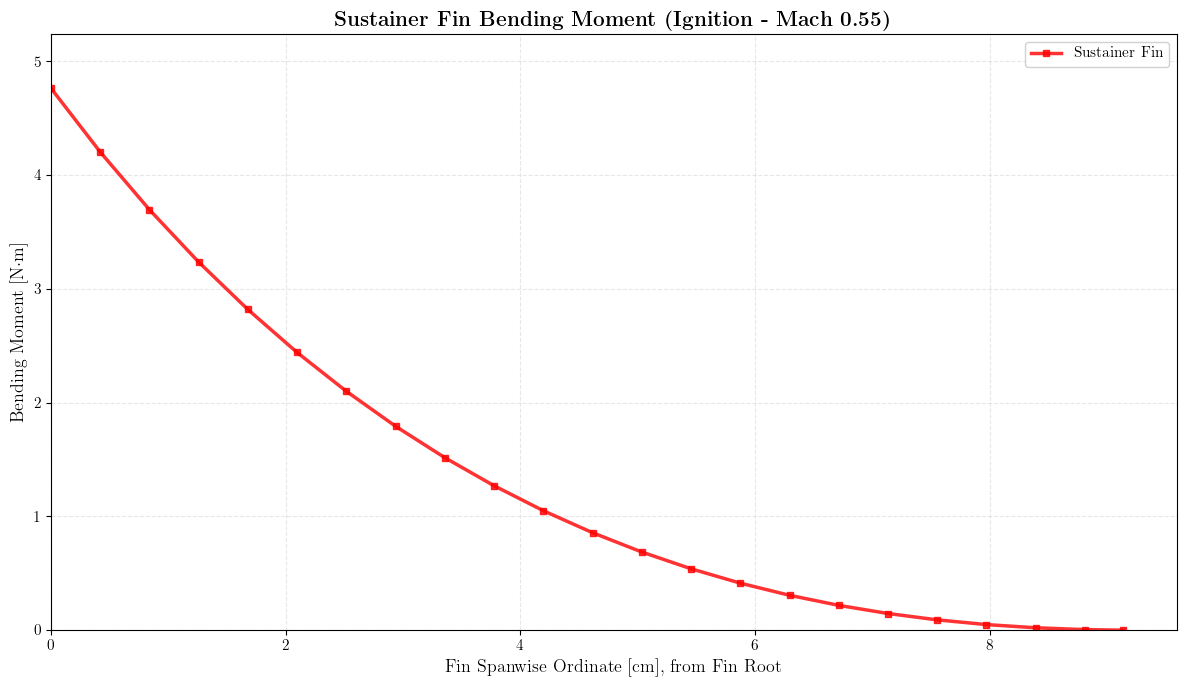

In [63]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(fin1_df_055['span_cm'], fin1_df_055['moment_Nm'], 
        'r-', linewidth=2.5, marker='s', markersize=5, 
        label=r'Sustainer Fin', alpha=0.8)
ax.set_xlabel(r'Fin Spanwise Ordinate [cm], from Fin Root', fontsize=13)
ax.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Sustainer Fin Bending Moment (Ignition - Mach 0.55)}', fontsize=15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, max(fin1_df_055['span_cm']) * 1.05)
ax.set_ylim(0, max(fin1_df_055['moment_Nm']) * 1.1)
plt.tight_layout()
plt.savefig('fin_bending_mach055_ignition.pdf', dpi=300, bbox_inches='tight')

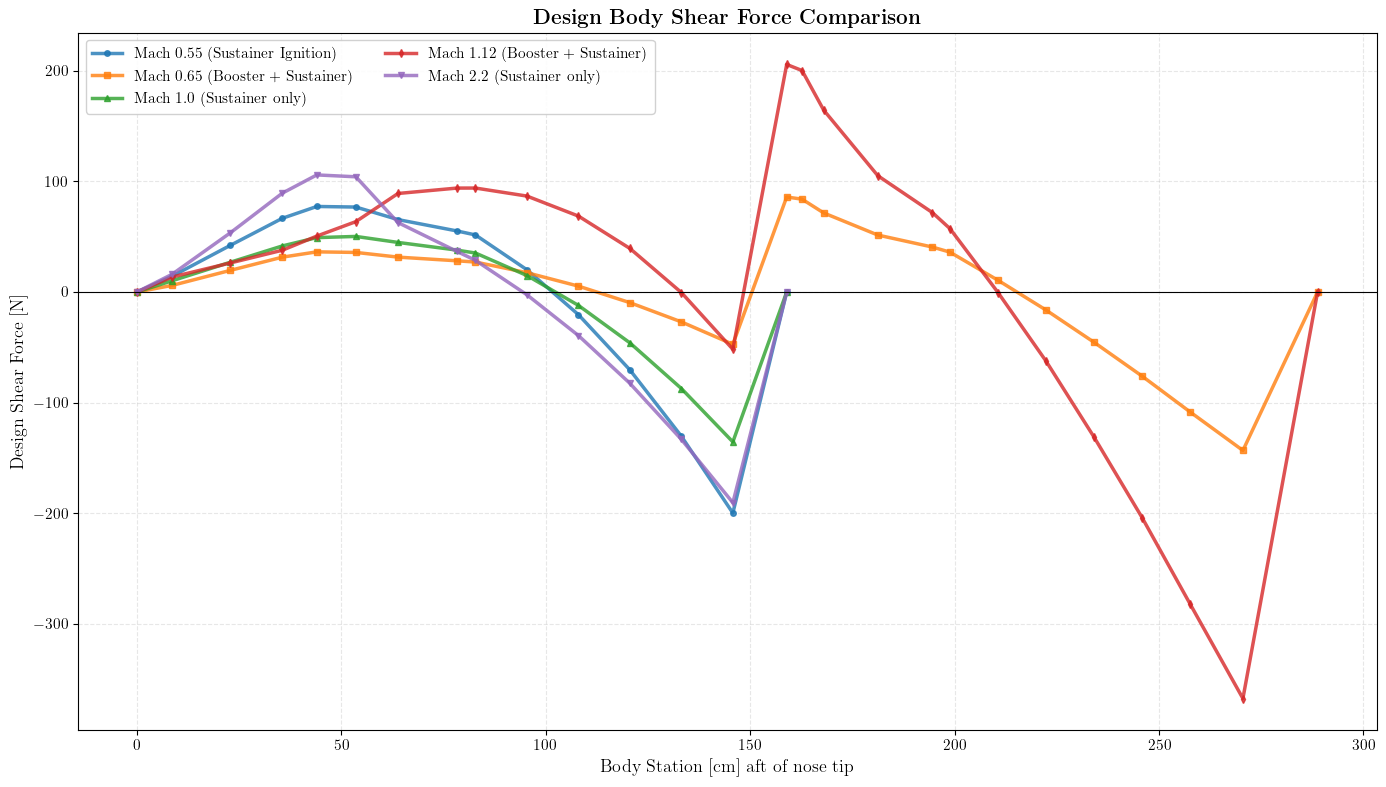

In [72]:
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(body_df_055['station_cm'], body_df_055['design_shear_N'], 
        linewidth=2.5, marker='o', markersize=4, label=r'Mach 0.55 (Sustainer Ignition)', alpha=0.8)
ax.plot(body_df_065['station_cm'], body_df_065['design_shear_N'], 
        linewidth=2.5, marker='s', markersize=4, label=r'Mach 0.65 (Booster + Sustainer)', alpha=0.8)
ax.plot(body_df_10['station_cm'], body_df_10['design_shear_N'], 
        linewidth=2.5, marker='^', markersize=4, label=r'Mach 1.0 (Sustainer only)', alpha=0.8)
ax.plot(body_df_112['station_cm'], body_df_112['design_shear_N'], 
        linewidth=2.5, marker='d', markersize=4, label=r'Mach 1.12 (Booster + Sustainer)', alpha=0.8)
ax.plot(body_df_22['station_cm'], body_df_22['design_shear_N'], 
        linewidth=2.5, marker='v', markersize=4, label=r'Mach 2.2 (Sustainer only)', alpha=0.8)

ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Design Shear Force [N]', fontsize=13)
ax.set_title(r'\textbf{Design Body Shear Force Comparison}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9, ncol=2)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('comparison_body_shear.pdf', dpi=300, bbox_inches='tight')

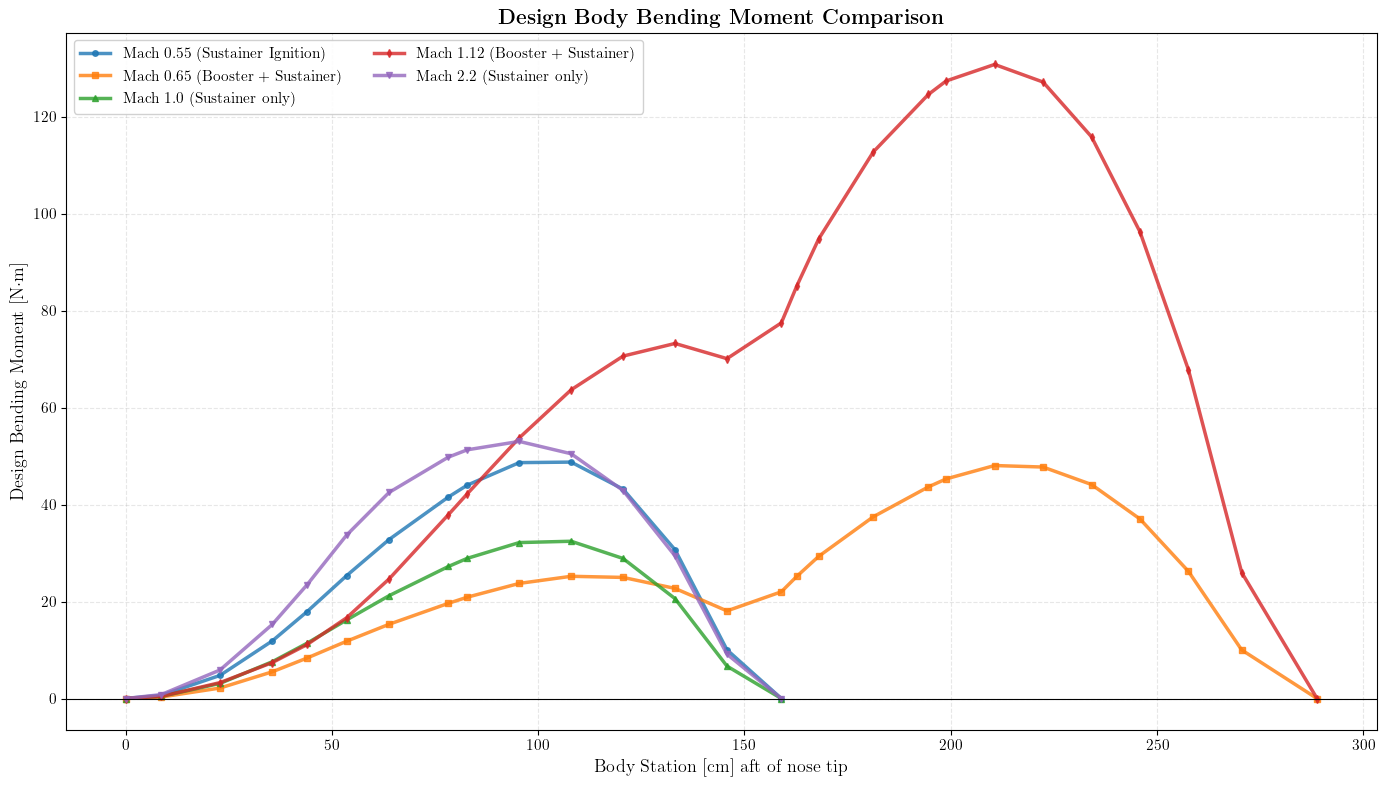

In [73]:
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(body_df_055['station_cm'], body_df_055['design_moment_Nm'], 
        linewidth=2.5, marker='o', markersize=4, label=r'Mach 0.55 (Sustainer Ignition)', alpha=0.8)
ax.plot(body_df_065['station_cm'], body_df_065['design_moment_Nm'], 
        linewidth=2.5, marker='s', markersize=4, label=r'Mach 0.65 (Booster + Sustainer)', alpha=0.8)
ax.plot(body_df_10['station_cm'], body_df_10['design_moment_Nm'], 
        linewidth=2.5, marker='^', markersize=4, label=r'Mach 1.0 (Sustainer only)', alpha=0.8)
ax.plot(body_df_112['station_cm'], body_df_112['design_moment_Nm'], 
        linewidth=2.5, marker='d', markersize=4, label=r'Mach 1.12 (Booster + Sustainer)', alpha=0.8)
ax.plot(body_df_22['station_cm'], body_df_22['design_moment_Nm'], 
        linewidth=2.5, marker='v', markersize=4, label=r'Mach 2.2 (Sustainer only)', alpha=0.8)

ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Design Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Design Body Bending Moment Comparison}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9, ncol=2)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('comparison_body_moment.pdf', dpi=300, bbox_inches='tight')

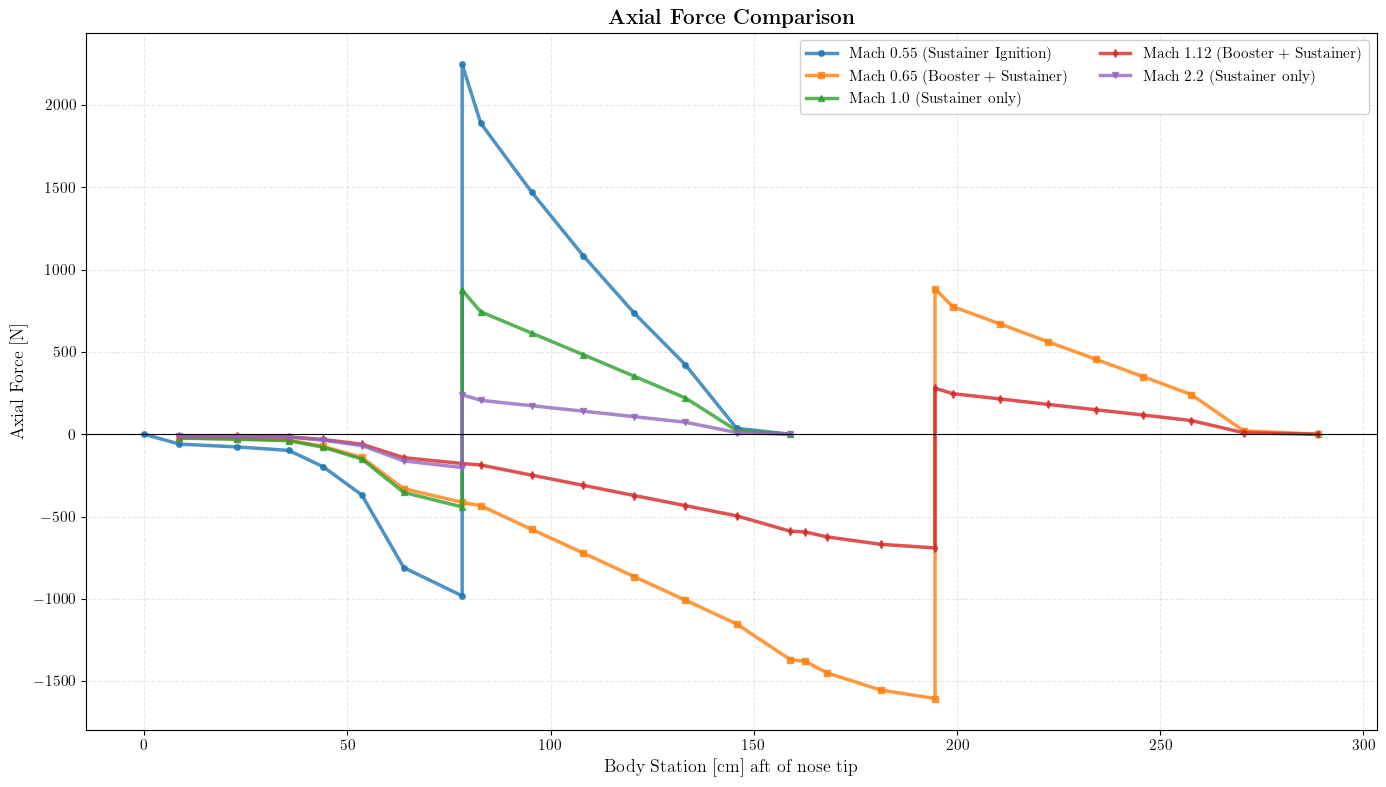

In [74]:
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(axial_df_055['station_cm'], axial_df_055['force_N'], 
        linewidth=2.5, marker='o', markersize=4, label=r'Mach 0.55 (Sustainer Ignition)', alpha=0.8)
ax.plot(axial_df_065['station_cm'], axial_df_065['force_N'], 
        linewidth=2.5, marker='s', markersize=4, label=r'Mach 0.65 (Booster + Sustainer)', alpha=0.8)
ax.plot(axial_df_10['station_cm'], axial_df_10['force_N'], 
        linewidth=2.5, marker='^', markersize=4, label=r'Mach 1.0 (Sustainer only)', alpha=0.8)
ax.plot(axial_df_112['station_cm'], axial_df_112['force_N'], 
        linewidth=2.5, marker='d', markersize=4, label=r'Mach 1.12 (Booster + Sustainer)', alpha=0.8)
ax.plot(axial_df_22['station_cm'], axial_df_22['force_N'], 
        linewidth=2.5, marker='v', markersize=4, label=r'Mach 2.2 (Sustainer only)', alpha=0.8)

ax.axhline(y=0, color='k', linestyle='-', linewidth=0.8)
ax.set_xlabel(r'Body Station [cm] aft of nose tip', fontsize=13)
ax.set_ylabel(r'Axial Force [N]', fontsize=13)
ax.set_title(r'\textbf{Axial Force Comparison}', fontsize=15)
ax.legend(loc='best', fontsize=11, framealpha=0.9, ncol=2)
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('comparison_axial_force.pdf', dpi=300, bbox_inches='tight')

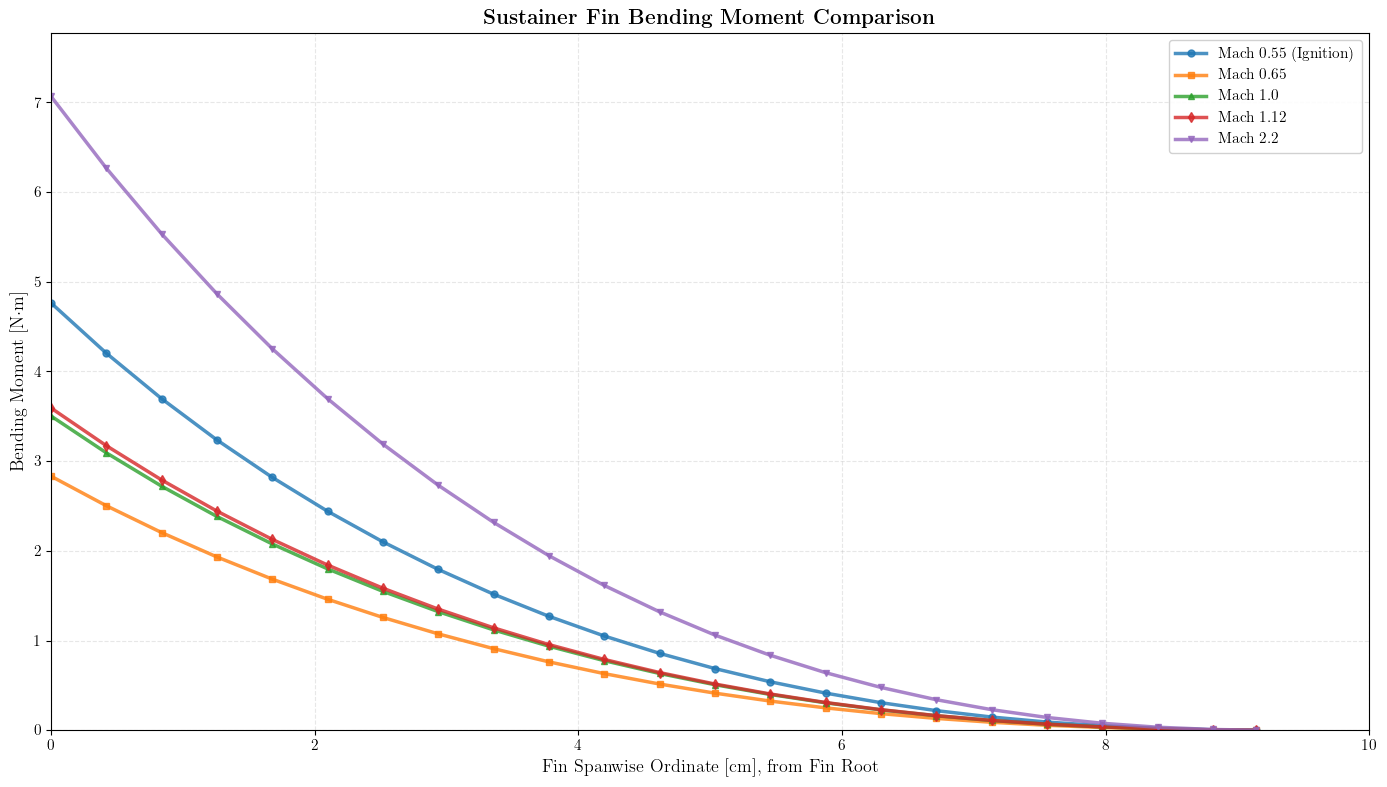

In [68]:
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(fin1_df_055['span_cm'], fin1_df_055['moment_Nm'], 
        linewidth=2.5, marker='o', markersize=5, label=r'Mach 0.55 (Ignition)', alpha=0.8)
ax.plot(fin2_df_065['span_cm'], fin2_df_065['moment_Nm'], 
        linewidth=2.5, marker='s', markersize=5, label=r'Mach 0.65', alpha=0.8)
ax.plot(fin1_df_10['span_cm'], fin1_df_10['moment_Nm'], 
        linewidth=2.5, marker='^', markersize=5, label=r'Mach 1.0', alpha=0.8)
ax.plot(fin2_df_112['span_cm'], fin2_df_112['moment_Nm'], 
        linewidth=2.5, marker='d', markersize=5, label=r'Mach 1.12', alpha=0.8)
ax.plot(fin1_df_22['span_cm'], fin1_df_22['moment_Nm'], 
        linewidth=2.5, marker='v', markersize=5, label=r'Mach 2.2', alpha=0.8)

ax.set_xlabel(r'Fin Spanwise Ordinate [cm], from Fin Root', fontsize=13)
ax.set_ylabel(r'Bending Moment [N$\cdot$m]', fontsize=13)
ax.set_title(r'\textbf{Sustainer Fin Bending Moment Comparison}', fontsize=15)
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 10)
ax.set_ylim(0, max(fin1_df_055['moment_Nm'].max(), fin1_df_22['moment_Nm'].max()) * 1.1)
plt.tight_layout()
plt.savefig('comparison_sustainer_fins.pdf', dpi=300, bbox_inches='tight')

In [32]:
data= '''0.34511755659603693, 168.76967345623825
0.5877944056359556, 263.76183146774065
1.2349326697424043, 531.2182001339743
1.5585018017956287, 665.6252077378176
1.882070933848853, 790.5286895514901
2.4179823088120056, 1025.4015412228528
2.1247477828887718, 885.5639474531977
3.1359013205550976, 1212.304215096211
3.9448241506881576, 1257.5590998113094
4.834639263834525, 1169.6823418554454
5.218877608147729, 1089.210928671142
5.967131226020811, 1064.0327564478325
6.856946339167177, 999.6062569352466
7.746761452313542, 947.0283090571593
8.636576565459912, 892.0641945304583
9.526391678606277, 835.9481374837351
10.416206791752646, 790.5286895514901
11.306021904899012, 743.1344830134958
12.195837018045378, 703.6393108985008
13.085652131191747, 658.2198629662562
13.975467244338112, 625.1426563199475
14.622605508444561, 715.5866004632871
15.172673032935045, 983.8575570543921
14.98662078200444, 848.9074908339676
15.593312904604236, 1089.210928671142
15.876435895150806, 1214.1144104848145
16.200005027204032, 1336.3025992155813
16.564020300763907, 1481.2992498427575
17.008927857337092, 1647.6562060554606
17.831332734639037, 1978.0168644756818
17.453835413910273, 1802.7899508588193
17.696512262950193, 1882.0765088796725
18.30320438554999, 2089.1176064512492
18.667219659109865, 2215.51449946052
19.314357923216313, 2284.4335748011868
20.053944510766545, 2166.5357842317217
20.48280201118629, 2032.9261245966682
21.25577271553566, 1943.0197536293388
22.064695545668723, 1823.8211300100543
22.954510658815085, 1704.3482343621936
23.844325771961454, 1585.8627180172075
24.734140885107823, 1487.618477381157
25.623955998254193, 1395.7922022137927
26.513771111400555, 1316.3081683323649
27.403586224546924, 1240.7736516624368
28.293401337693293, 1172.6444797640697
29.228156608069273, 1099.8709681818104
30.073031563986024, 1046.0953657789391
30.962846677132394, 993.4351362922785
31.827382951837112, 934.5749875996489
32.74247690342513, 906.7103208564354
33.6322920165715, 864.5821372671062
34.52210712971785, 824.5932755006738
35.41192224286422, 784.604413734241
36.30173735601059, 748.0713795278702
37.19155246915696, 710.5509660186249
38.08136758230333, 676.9800697208789
38.9711826954497, 644.3965527260079
39.8812208793494, 608.6040529967931
40.75081292174242, 575.7736911762036
41.64062803488879, 543.1901741813326
42.53044314803516, 512.5814157922114
43.42025826118153, 480.4915884487773
44.3100733743279, 449.88283005965604
45.19988848747427, 416.31193376191004
46.08970360062062, 389.15900293285085
46.97951871376699, 358.05655489229184
47.86933382691336, 331.3973137146704
48.75914894005973, 297.82641741692396
49.6489640532061, 268.2050383306778
50.53877916635247, 239.0773488958689
51.428594279498824, 210.9370387639342
52.318409392645194, 186.74624584350022
53.20822450579156, 153.66903919719152
54.09803961893793, 124.04766011094489
56.605700392350414, 20.076619518220014
57.49551550549678, 8.030592023146255
58.38533061864315, -9.248545777164054
59.27514573178952, -22.281952575112427
62.834406184374984, -155.38068260264663
63.69894245907969, -194.64752325385234
64.61403641066772, -210.1802339122023
65.50385152381409, -237.82685439269972
66.39366663696046, -263.00502661600876
67.26730329350416, -291.2440746782304
68.17329686325319, -318.29826757700175
69.06311197639955, -347.4259570118111
69.95292708954592, -376.0599567951831
70.84274220269229, -398.2759911098674
71.73255731583866, -423.94785298461466
72.62237242898502, -449.6197148593619
73.51218754213139, -478.74740429417034
74.40200265527776, -502.93819721460477
75.29181776842412, -525.15423152929
76.1816328815705, -549.8387141011626
77.07144799471686, -575.510575975909
77.96126310786322, -596.7392309877196
78.85107822100959, -621.9174032110286
79.76785742849373, -633.1899835855165
80.63070844730233, -664.374713234648
81.5205235604487, -684.615988943583
82.41033867359506, -705.8446439553936
83.30015378674143, -724.1111610585785
84.18996889988779, -743.365057464639
85.07978401303416, -764.1000228250114
85.96959912618053, -781.3791606253226
86.82705732612156, -797.3747053318948
87.74922935247326, -816.9248155288178
88.63904446561963, -830.2544361176288
89.52885957876599, -840.6219187978149
90.41867469191236, -855.4326083409387
91.30848980505873, -871.2306771869362
92.1983049182051, -879.6234012613722
93.08812003135147, -892.9530218501832
93.97793514449783, -898.8772976674327
94.90145537556641, -917.9035482897743
95.68206590664481, -928.4328514668205
96.64738048393693, -926.0302284964928
97.5371955970833, -936.3977111766781
98.42701071022967, -936.3977111766781
99.31682582337604, -936.3977111766781
100.2066409365224, -935.2457686566577
101.09645604966876, -936.3977111766781
101.98627116281513, -936.3977111766781
102.8760862759615, -936.3977111766781
103.76590138910787, -936.3977111766781
104.65571650225424, -936.3977111766781
105.5455316154006, -936.3977111766781
106.43534672854696, -936.3977111766781
107.32516184169333, -936.3977111766781
108.2149769548397, -936.3977111766781
109.10479206798607, -936.3977111766781
109.99460718113244, -919.1185733763687
110.8844222942788, -914.6753665134311
111.77423740742518, -914.6753665134311
112.66405252057153, -910.2321596504935
113.5538676337179, -892.9530218501832
114.44368274686427, -892.9530218501832
115.33349786001064, -885.0539874271844
116.223312973157, -876.6612633527484
117.11312808630336, -873.2054357926863
118.00294319944973, -854.9389186895005
118.8927583125961, -854.9389186895005
119.78257342574247, -838.1534705406275
120.67238853888884, -833.2165740262535
121.56220365203521, -823.3427809975037
122.45201876518158, -816.9248155288178
123.34183387832795, -808.5320914543818
124.23164899147432, -795.2024708655699
125.12146410462069, -791.2529536540706
126.01127921776705, -773.4801262023229
126.95165200779672, -785.472670651824
127.46734031200654, -784.3412985339464
61.33915574963609, -100.97719869706907
60.53857350800581, -100.97719869706907
60.029112081513816, -52.1172638436492
0.7860262008733656, 387.62214983713284
55.880640465793306, 65.14657980455968
55.080058224163025, 84.69055374592745
'''

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO 
from matplotlib import rcParams

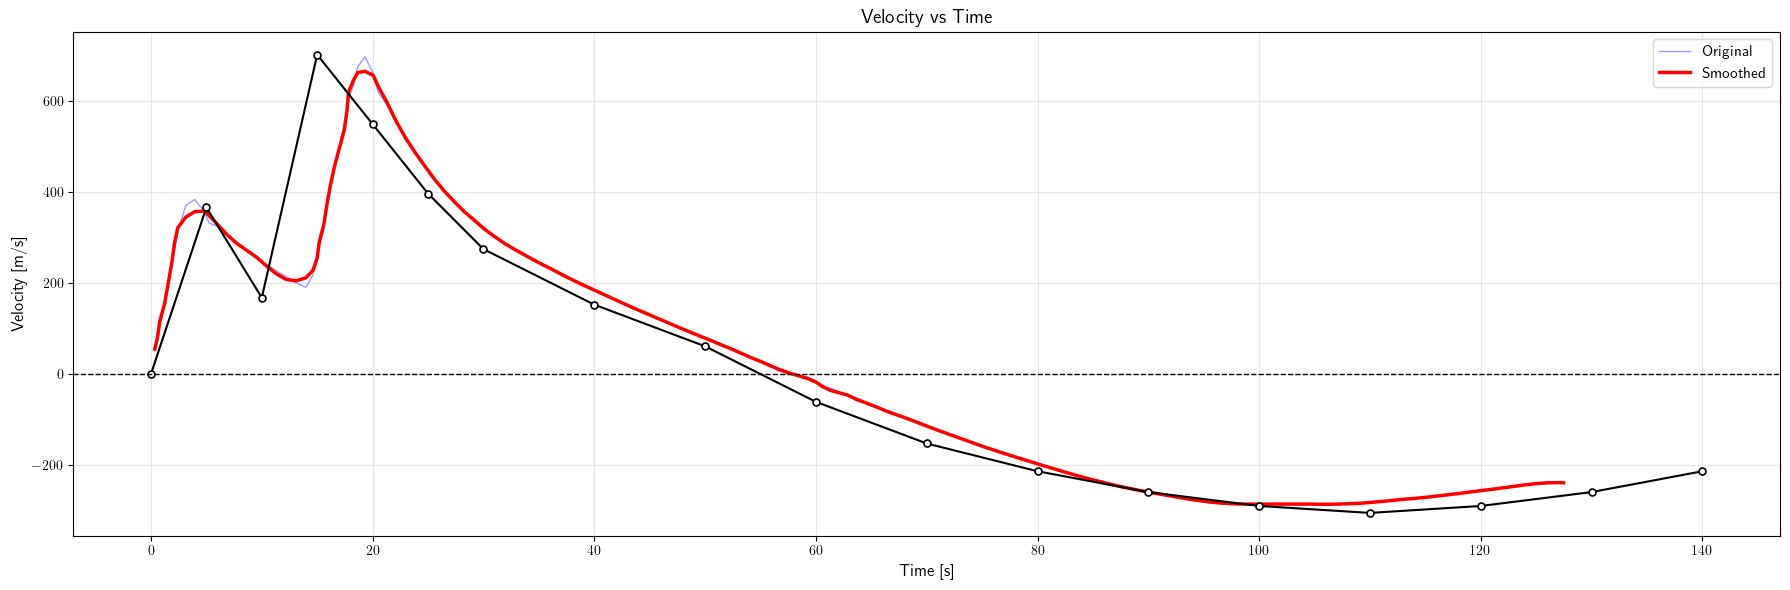

In [34]:
from scipy.signal import savgol_filter

# Your data parsing code
FT_TO_M = 0.3048  # Conversion factor: ft/s to m/s
lines = data.strip().split('\n')
time = []
velocity_ms = []

for line in lines:
    t, v_fts = line.split(',')
    time.append(float(t))
    velocity_ms.append(float(v_fts) * FT_TO_M)  # Convert to m/s

df = pd.DataFrame({'Time_s': time, 'Velocity_m_s': velocity_ms})    
df.sort_values(by='Time_s', inplace=True)

# Apply Savitzky-Golay smoothing (best for preserving features)
window_length = 11  # Must be odd. Larger = smoother. Try 7, 11, 15, 21
polyorder = 3       # Polynomial order. 2-3 is usually good
df['Velocity_smooth'] = savgol_filter(df['Velocity_m_s'], window_length, polyorder)

# Plot
plt.figure(figsize=(18, 6))

# Original (light blue, thin)
plt.plot(df['Time_s'], df['Velocity_m_s'], 'b-', linewidth=1, alpha=0.4, label='Original')

# Smoothed (red, bold)
plt.plot(df['Time_s'], df['Velocity_smooth'], 'r-', linewidth=2.5, label='Smoothed')

plt.plot(time1, velocity_ft1 * FT_TO_M , 'k-', linewidth=1.5, 
        marker='o', markersize=5, 
        markerfacecolor='white', 
        markeredgecolor='black', 
        markeredgewidth=1.2)


plt.axhline(y=0, color='k', linestyle='--', linewidth=1)
plt.xlabel('Time [s]', fontsize=12)
plt.ylabel('Velocity [m/s]', fontsize=12)
plt.title('Velocity vs Time', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


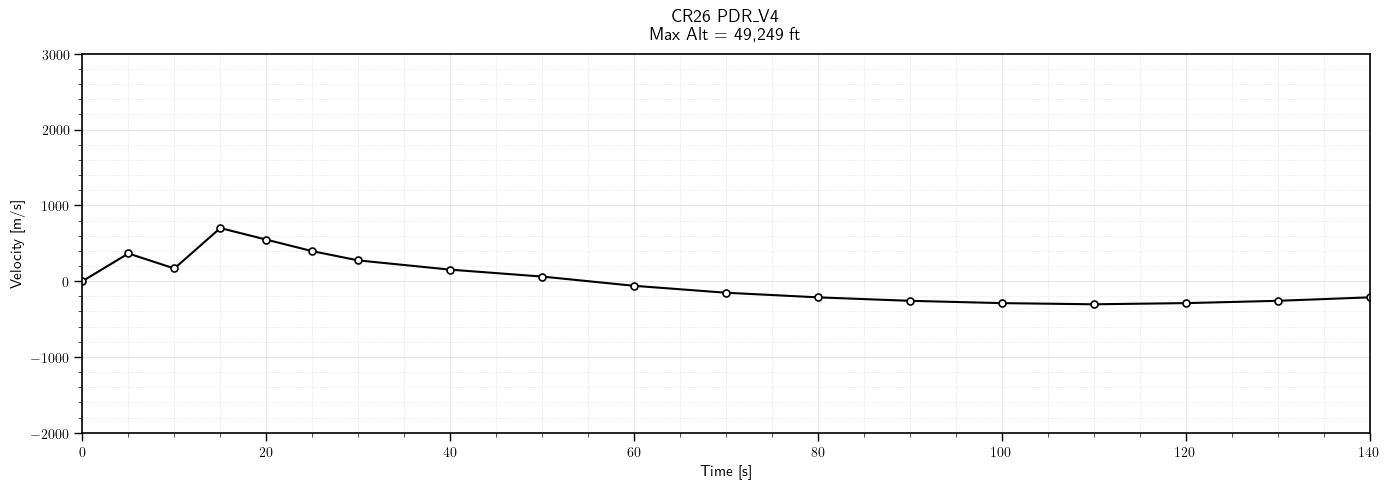

Plot created: CR26 PDR_V4
Max Altitude: 49,249 ft
Time range: 0.0 - 140.0 sec


AttributeError: 'list' object has no attribute 'min'

In [31]:
# ============================================================================
# YOUR DATA HERE
# ============================================================================
# Replace this with your actual data
# Format: time,velocity (in ft/s)
data = """0,0
5,1200
10,550
15,2300
20,1800
25,1300
30,900
40,500
50,200
60,-200
70,-500
80,-700
90,-850
100,-950
110,-1000
120,-950
130,-850
140,-700"""

# ============================================================================
# CONFIGURATION
# ============================================================================
mission_name = "CR26 PDR_V4"
max_altitude_ft = 49249  # Maximum altitude in feet

# Axis limits
x_min, x_max = 0, 140
y_min, y_max = -2000, 3000

# Tick intervals
x_major_tick = 20  # Major ticks every 20 seconds
y_major_tick = 1000  # Major ticks every 1000 ft/s

# ============================================================================
# DATA PARSING
# ============================================================================
lines = data.strip().split('\n')
time = []
velocity_fts = []

for line in lines:
    if line.strip():
        t, v = line.split(',')
        time.append(float(t))
        velocity_fts.append(float(v))

# Convert to arrays
time1 = np.array(time)
velocity_ft1 = np.array(velocity_fts)

# ============================================================================
# PLOTTING SETUP (matching original style)
# ============================================================================
rcParams['font.family'] = 'sans-serif'
rcParams['font.size'] = 10
rcParams['axes.labelsize'] = 11
rcParams['axes.titlesize'] = 12

# Create figure
fig, ax = plt.subplots(figsize=(14, 5))

# Plot with black line and white-filled markers (like original)
ax.plot(time1, velocity_ft1 * FT_TO_M, 'k-', linewidth=1.5, 
        marker='o', markersize=5, 
        markerfacecolor='white', 
        markeredgecolor='black', 
        markeredgewidth=1.2)

# ============================================================================
# FORMATTING (matching original)
# ============================================================================

# Title with mission name and max altitude
ax.set_title(f'{mission_name}\nMax Alt = {max_altitude_ft:,} ft', 
             fontsize=13, fontweight='normal', pad=10)

# Axis labels
ax.set_xlabel('Time [s]', fontsize=11)
ax.set_ylabel('Velocity [m/s]', fontsize=11)

# Set axis limits
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Major gridlines (solid)
ax.grid(True, which='major', linestyle='-', linewidth=0.5, color='gray', alpha=0.3)

# Minor gridlines (dotted)
ax.grid(True, which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=0.3)
ax.minorticks_on()

# Tick parameters
ax.tick_params(axis='both', which='major', length=6, width=1)
ax.tick_params(axis='both', which='minor', length=3, width=0.5)

# Box around plot
for spine in ax.spines.values():
    spine.set_linewidth(1.2)

# Set major ticks
ax.set_xticks(np.arange(x_min, x_max + 1, x_major_tick))
ax.set_yticks(np.arange(y_min, y_max + 1, y_major_tick))

# ============================================================================
# SAVE
# ============================================================================
plt.tight_layout()
#plt.savefig('velocity_plot_reproduction.png', dpi=300, bbox_inches='tight', facecolor='white')
#plt.savefig('velocity_plot_reproduction.pdf', bbox_inches='tight', facecolor='white')
plt.show()

print(f"Plot created: {mission_name}")
print(f"Max Altitude: {max_altitude_ft:,} ft")
print(f"Time range: {time[0]:.1f} - {time[-1]:.1f} sec")
print(f"Velocity range: {velocity_fts.min():.1f} - {velocity_fts.max():.1f} ft/s")
print(f"Data points: {len(time)}")